<h1 style="text-align:center;">Unsupervised learning</h1>

<br>

<h2 style="text-align:center;">Author: Dr. Suborna Ahmed</h2>

 ***

## Introduction

In the realm of machine learning, unsupervised learning plays a crucial role when labeled data or independent variables are not readily available. This chapter explores two fundamental tasks within unsupervised learning: dimension reduction using Principal Component Analysis (PCA) and clustering analysis. PCA provides a method to compress high-dimensional datasets while retaining key information, aiding in pattern exploration. On the other hand, clustering analysis categorizes data points into homogeneous groups, unraveling hidden structures within the dataset. The chapter delves into the popular K-means clustering algorithm and hierarchical clustering methods. To better understand the methods, some practical examples are provided during this chapter.

#### Learning Objectives 

1. Introducing unsupervised learning
2. Dimension reduction techniques: Principal Components Analysis
3. Clustering Analysis 
    * K-means clustering </br>
    * Hierarchical clustering </br>

#### Readings
For this lecture you need to read sections from the book James et al. (2021). The book is available online through the UBC library:

* James, G., Witten, D., Hastie, T., Tibshirani, R. (2021). An Introduction to Statistical Learning: With Applications in R. In: An Introduction to Statistical Learning. Springer Texts in Statistics. Springer, New York, NY. https://doi.org/10.1007/978-1-0716-1418-1_2 

Relevant sections (read in this order):
* **12.1.** The Challenge of Unsupervised Learning (pp. 497-498)
* **12.4.** Clustering Methods (pp. 516-532)
* **6.3.1.** Principal Components Regression  (only read "An Overview of Principal Components Analysis", pp. 252-256)
* **12.2.** Principal Components Analysis (pp. 498-510)

#### References
* James, G., Witten, D., Hastie, T., Tibshirani, R. (2021).An Introduction to Statistical Learning: With Applications in R. In: An Introduction to Statistical Learning. Springer Texts in Statistics. Springer, New York, NY. https://doi.org/10.1007/978-1-0716-1418-1_2 

* Randler, Christoph. 2021. "An Analysis of Heterogeneity in German Speaking Birdwatchers Reveals Three Distinct Clusters and Gender Differences" Birds 2, no. 3: 250-260. https://doi.org/10.3390/birds2030018

* [scikit-learn: Clustering](https://scikit-learn.org/stable/modules/clustering.html#hierarchical-clustering)

#### Required Packages

The following code cell includes all the necessary packages to complete this notebook. It is a good idea to run this right now to make sure you have no issues. 

In [1]:
### Load packages
# Data organization
import pandas as pd
import numpy as np
import os

# For plotting
import matplotlib.pyplot as plt
import seaborn as sns

# For modelling
from sklearn import  datasets
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from scipy.cluster.hierarchy import dendrogram
from yellowbrick.cluster import KElbowVisualizer

*Note: If you don't have the 'yellowbrick' module installed, you should first install it by running the following code in a cell:`pip install yellowbrick`.*

## 1. Introducing Unsupervised Learning

When creating statistical models, we typically aim to predict a label (classification) or a continuous variable (regression). In this case, models and regressors can be trained and validated using input data. However, there are cases where labels or independent variables may not be available. In such situations, we can utilize simple data visualizations, such as scatterplots, to identify groupings in the dataset. But determining which data points are relatively similar can be challenging. This is where unsupervised learning becomes valuable.

The two primary unsupervised learning tasks are clustering and dimension reduction. Clustering analysis assigns data points to homogeneous groups, while dimension reduction compresses a large set of variables onto a new feature subspace without losing 'important' information. Unsupervised learning is widely used for exploratory data analysis. Dimension reduction, in particular, is sometimes employed in combination with supervised learning. This is especially relevant when supervised learning becomes computationally intensive with a large number of dimensions. Principal Component Analysis (PCA) is one such technique used to replace correlated variables, reducing the risk of overfitting by using too many variables.

<br>
<div style="text-align: center;">
<img src=https://i.imgur.com/ZQq40iq.jpg alt="image" width="600"/>
</div>
<br>
<div style="text-align: center;">
     <strong>Figure 1. Two primary unsupervised learning tasks: Clustering and Dimension reduction. [James, G., Witten, D., Hastie, T., Tibshirani, R. (2021). An Introduction to Statistical Learning: With Applications in R.] (Dataset: The Iris dataset comprises 150 samples of iris flowers, categorized into three species: setosa, versicolor, and virginica. X-axis represents sepal length, Y-axis represents petal length, and Z-axis represents sepal width.)</strong>
    </div>
    <br>


Some of the challenges with unsupervised learning are:
* Subjectivity: Results are subjective as they heavily rely on the choice of data variables and selected statistics, such as dissimilarity metrics.

* Sensitivity to Perturbations: Unsupervised learning models can be sensitive to small variations or perturbations in the data, potentially yielding different outcomes with slight changes.

* Difficulty in Assessing Quality: Evaluating the quality of results is challenging due to the absence of validation data. Unlike supervised learning, where predefined criteria exist through labels, unsupervised learning lacks such benchmarks for assessment.

## 2. Principal Component Analysis

PCA is a method used to reduce the dimensionality of a dataset without losing any "interesting" information, where "interesting" information is defined as the variability present in the original dataset.

When to use it?
* When it is challeninging to explore patterns in a dataset with a large number of variables. If you are in doubt about whether to use PCA or not, think about the number of scatterplots you need to plot and interpret...
* As a method to reduce the number of variables for predictive modelling, while ensuring predictor variables are not correlated.


PCA reduces the dimensionality of a dataset while maintaining its variance. The optimal number of new dimensions, also called principal components, in the new tranformed datset depends on how much variance is explained by each component. We will discuss how to determine the number of principal components later.

To understand the mathemetical concepts and terminalogy of PCA we will look at a transformation of two variables into two principal components:

##### Panel 1
Panel 1 shows a measures from sampled tree seedlings in a growth experiment. The scatterplot displays total sprout length (centimeters) and the number of internodes of each sprout. Internodes are the intervals between buds, twigs and leaves (nodes) growing out of the stem. The first principal component should capture maximum variance. The solid line shows the direction in which variance is largest, so this will be the direction of the first principal component. 

The dotted line shows the second direction in which variance is largest. This new line, which is the second principal component, is uncorrelated with the solid line because it was placed perpendicular to the first principal component. New principal components always maximize variance while minimizing correlation with previous principal components.


<br>
<div style="text-align: center;">
<img src=https://i.imgur.com/Uihmhbt.jpg alt="image" width="600"/>
</div>
<br>
<div style="text-align: center;">
     <strong>Figure 2.  Scatterplot of sprout length (cm) and internode count. Solid line: first principal component capturing maximum variance. Dotted line: uncorrelated second principal component.</strong>
    </div>
    <br>



##### Panel 2
We just described the principal components' lines/vectors as the directions in feature space along which the data varies most. Another way to look at the first principal component is as the vector that is as close to the data as possible. In this panel the sum of squared perpendicular distances between the solid line and data points is as small as possible.

<br>
<div style="text-align: center;">
<img src=https://i.imgur.com/1Ri74LI.jpg alt="image" width="600"/>
</div>
<br>
<div style="text-align: center;">
     <strong>Figure 3. Another way to look at the first principal component (as the vector closest to the data, minimizing squared perpendicular distances to data points)</strong>
    </div>
    <br>

##### Panel 3

Loadings, eigenvectors, and eigenvalues are terms you will encounter when working with PCA.
**Loadings** define the directions of the principal components, in other words, the directions in which data varies the most. After solving the loadings through an optimization problem, which is briefly explained later, the original variables are transformed into principal components. The orientation of the new x-axis compared to the original axis is called the **eigenvector**. **Eigenvalues** are the variances explained by the PCs. In the end, $Loadings$ = $Eigenvectors$ * $\sqrt{Eigenvalues}$


<br>
<div style="text-align: center;">
<img src=https://i.imgur.com/2FxvtF5.jpg alt="image" width="600"/>
</div>
<br>
<div style="text-align: center;">
     <strong> Figure 4. Scatter plot of PC1 (X-axis) and PC2 (Y-axis)</strong>
    </div>
    <br>


##### Panel 4

The first principal component that was displayed in the previous panels can be summarized 
by this equation:

<br>
<div style="text-align: center;">
<img src=https://i.imgur.com/nSh92zz.jpg alt="image" width="600"/>
</div>
<br>
<div style="text-align: center;">
     <strong>Figure 5. Calculation of Principal Component Scores for PC1</strong>
    </div>
    <br>

Here φ1 = 21.939 and φ2 = 3.761 are the principal components' loadings describing its' direction. $sproutlength_{i}$ is a value of the variable `total sprout length`, whereas $\overline{sproutlength}$ indicates the mean of all values. This is similar for $internotes$, which refers to `the number of internodes`. Using this equation, we can convert all values in the original dataset to principal component 1 scores.

##### Panel 5
Now we generally know what loadings are, let's dig a little deeper in how they are defined. The loadings are defined while solving an optimization problem. For every possible linear combination of $sproutlength$ and $internotes$ total variance should be maximized. The size of the loadings is constrained so that their sum of squares is equal to one. If loadings are not constrained, loadings could be arbitrarily large to create an arbitrarily large
variance. This is the optimization problem for defining loadings:

<br>
<div style="text-align: center;">
<img src=https://i.imgur.com/VONoBvG.jpg alt="image" width="600"/>
</div>
<br>

##### A Complete Overview of PCA

Recapping the key points, let's look at an overview of PCA methodology:

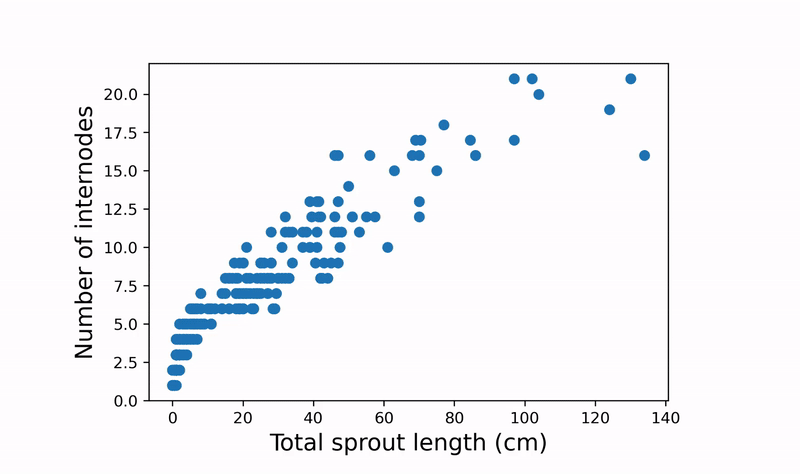

### Example 1: PCA analysis on ten variables

#### Data set
The Forest Cover Type dataset from Kaggle will be used (you can find the Kaggle page here: https://www.kaggle.com/competitions/forest-cover-type-prediction/data). 

The following description is reported:
"The study area includes four wilderness areas located in the Roosevelt National Forest of northern Colorado. Each observation is a 30m x 30m patch. You are asked to predict an integer classification for the forest cover type."

Data Fields:
* Elevation - Elevation in meters
* Aspect - Aspect in degrees azimuth
* Slope - Slope in degrees
* Horizontal_Distance_To_Hydrology - Horz Dist to nearest surface water features
* Vertical_Distance_To_Hydrology - Vert Dist to nearest surface water features
* Horizontal_Distance_To_Roadways - Horz Dist to nearest roadway
* Hillshade_9am (0 to 255 index) - Hillshade index at 9am, summer solstice
* Hillshade_Noon (0 to 255 index) - Hillshade index at noon, summer solstice
* Hillshade_3pm (0 to 255 index) - Hillshade index at 3pm, summer solstice
* Horizontal_Distance_To_Fire_Points - Horz Dist to nearest wildfire ignition points
* Wilderness_Area (4 binary columns, 0 = absence or 1 = presence) - Wilderness area designation
* Soil_Type (40 binary columns, 0 = absence or 1 = presence) - Soil Type designation
* Cover_Type (7 types, integers 1 to 7) - Forest Cover Type designation

Below we read the dataset, rename Forest Cover Type labels, select rows randomly, and select the nominal variables.

In [2]:
# Read Kaggle Forest cover data
df = pd.read_csv('covtype.csv')

# Relabelling values in "Cover_type" column
df["Cover_Type"].replace(1, 'Spruce/Fir', inplace=True)
df["Cover_Type"].replace(2, 'Lodgepole Pine', inplace=True)
df["Cover_Type"].replace(3, 'Ponderosa Pine', inplace=True)
df["Cover_Type"].replace(4, 'Cottonwood/Willow', inplace=True)
df["Cover_Type"].replace(5, 'Aspen', inplace=True)
df["Cover_Type"].replace(6, 'Douglas-fir', inplace=True)
df["Cover_Type"].replace(7, 'Krummholz', inplace=True)

# Select 300 data points randomly
df = df.groupby("Cover_Type").sample(n=300, random_state=2)

# For this excercise we would only like to keep the following variables.
features = ['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology',
       'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways',
       'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm',
       'Horizontal_Distance_To_Fire_Points']
selectDf = df.loc[:,features]

# Inspect
selectDf.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points
388308,2769,76,6,285,39,2671,228,229,136,1986
2797,2769,309,13,0,0,2143,184,231,187,787
2774,2753,325,10,60,15,2037,196,230,173,722
507654,2804,82,19,90,41,1698,242,204,84,1595
13566,2888,48,7,319,56,824,223,225,137,1500


#### Standardization
Standardizing a dataset is necessary as it removes biases in the original variables. For example, if some variables have a large variance and some small, the variable with large variance will be dominating the first Principal component. To address this, we standardize the variables by setting their mean to 0 and variance to 1.

In [3]:
### Standardize and scale data

scaler = StandardScaler() # 1. Initialize scaler from sklearn
selectDf = scaler.fit_transform(selectDf) # 2. Fit and transform
selectDf = pd.DataFrame(selectDf, columns= features) # 3. Convert Array back to Pandas Dataframe

# Inspect
selectDf.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points
0,0.049568,-0.707749,-1.226828,0.181608,-0.231497,0.647528,0.506162,0.449354,0.025364,0.426314
1,0.049568,1.396966,-0.380819,-1.086605,-0.854123,0.267192,-1.001021,0.538773,1.160559,-0.671719
2,0.011283,1.541496,-0.743394,-0.819613,-0.614652,0.190837,-0.589971,0.494064,0.848937,-0.731245
3,0.133317,-0.653550,0.344331,-0.686117,-0.199567,-0.053356,0.985721,-0.668389,-1.132089,0.068240
4,0.334314,-0.960676,-1.105969,0.332903,0.039904,-0.682927,0.334892,0.270515,0.047623,-0.018760


#### Apply PCA
The next code block initiates a PCA model. We will fit PCA to dataset and check how much of variance the components explain. In next step, a screeplot would be produced to assess how many components we should further investigate.

In [4]:
# 1. Initialize pca with default parameters
pca = PCA(n_components=10) 
# 2. Fit and transform
pcaFit = pca.fit_transform(selectDf) 
# 3. Convert Array back to Pandas Dataframe
pcaFitDf = pd.DataFrame(pcaFit,
                          columns=['PC1','PC2','PC3','PC4','PC5',
                                   'PC6','PC7','PC8','PC9','PC10']) 

# Inspect
pcaFitDf.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,-0.680958,-1.080917,-0.901950,-0.447183,0.184645,0.373437,-0.497685,-0.295368,-0.022636,0.016681
1,-1.182926,1.934390,-0.964949,0.463788,-0.815652,-0.187621,0.169052,-0.178086,-0.349689,-0.023995
2,-1.111432,1.584622,-0.867721,0.045536,-0.758993,-0.411249,0.257791,-0.601804,-0.432883,-0.001649
3,1.464630,-1.041865,-0.439161,0.392657,-0.167962,-0.290605,0.139537,0.043943,-0.262074,-0.033955
4,-0.103729,-0.708111,-0.490900,-1.108424,0.367065,0.831666,0.378321,0.081783,-0.256976,0.023754


#### Select an optimal number of principal components for further analysis

We performed PCA on ten variables, which means we can calculate ten principal components. It wouldn't make sense to look at them all. We need to determine the number of principal components we would like to retain in further exploratory analysis or modeling. In PCA, a screeplot is a plot that shows the eigenvalues of all principal components. This allows us to assess how much variance is explained by the first few components. If we would sum up all eigenvalues, this results in 1 (or 100% of variance explained).

In the next code block we create a screeplot. We can extract the eigenvalues using the `.explained_variance_ratio_` method, which are then plotted using the seaborn package. For convenience, we also added cumulative explained variance to the plot.

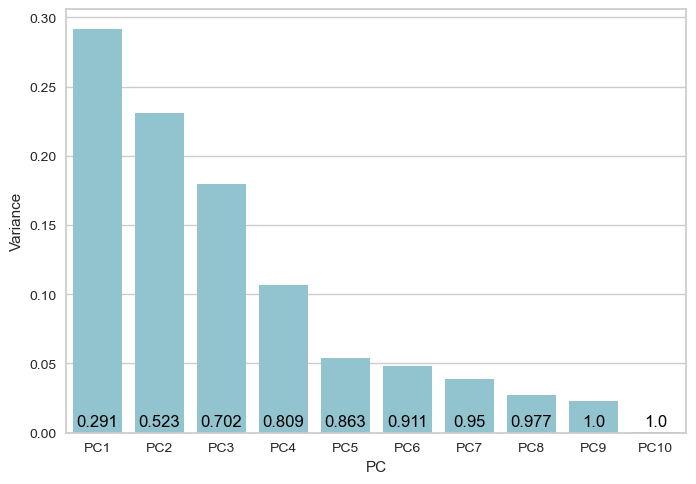

In [5]:
# 1. Get explained variance
explainedVar = pca.explained_variance_ratio_
# 2. Calculate cumalative explained variance
explainedVarCum = explainedVar.cumsum()
# 3. Convert to Pandas DataFrame
componentsDf = pd.DataFrame({'Variance':explainedVar,
             'PC':['PC1','PC2','PC3','PC4','PC5','PC6','PC7','PC8','PC9','PC10']})
# 4. Plot screeplot 
p1 = sns.barplot(x='PC',y="Variance", 
           data=componentsDf, color="c")
# 5. Add labels showing cumulative explained variance
j = 0
for i in explainedVarCum:
    p1.text(j, 0.005, round(i,3), color='black', ha="center")
    j+=1

So, how many components do we retain? This decision is ultimately subjective. We see two large steps in the plot, between PC2-PC3 and between PC3-PC4. 

#### Use PCA for exploratory analysis using biplots

A PCA biplot shows the PCA scores (scatterplot) and loadings of the components (as arrows on top of scatterplot).

In [6]:
def biplot(score, coeff, ax=None, pcLabels=[1,2], featureLabels=None, hue=None):
    ''' 
    ### Function to create a biplot (scatterplot with PCA loadings using matplotlib) ###
    ### Adapted from Prasad Ostwal: https://ostwalprasad.github.io/machine-learning/PCA-using-python.html ###
    
    ### Arguments: ###
    *Score: Fitted PCA scores, subset two principal components. e.g. via pcaFit[:,[0,1]] for PC1 and PC2
    *Coeff: Set of all eigenvectors, subset two principal components. e.g. via np.transpose(pca.components_[[0,1], :]) for PC1 and PC2
    *ax: Axis to be plotted on. This function has to be used after setting plt.subplots()
    *pcLabels: The labels of the Principal components. E.g. [1,2] for PC1 and PC2.
    *featureLabels: Names of variables in original dataset. Input is a list of strings.
    *hue: To visualize classes/clusters
    '''
    
    # Set theme Seaborn
    custom_params = {"axes.spines.right": False, "axes.spines.top": False}
    sns.set_theme(style="ticks", rc=custom_params)
    
    # Gather PC scores
    xs = score[:,0]
    ys = score[:,1]
    n = coeff.shape[0]
    scalex = 1.0/(xs.max() - xs.min())
    scaley = 1.0/(ys.max() - ys.min())
    
    # Plotting scatterplots
    if hue is None: # If 'hue' argument was provided
        sns.scatterplot(ax=ax, x=xs*scalex, y=ys*scaley, palette="tab10")
    else:  # If 'hue' argument was not provided
        sns.scatterplot(ax=ax, x=xs*scalex, y=ys*scaley, hue=hue, palette="tab10")
    
    # Plotting arrows (loadings)
    for i in range(n):
        ax.arrow(0, 0, coeff[i,0], coeff[i,1],color = 'black',alpha = 0.5) # arrow
        ax.set_xlabel("PC{}".format(str(pcLabels[0]))) # x axis label
        ax.set_ylabel("PC{}".format(str(pcLabels[1]))) # y axis label
    
    # Plotting labels with arrows (loadings)
        if featureLabels is None: # If original variable names were not provided
            ax.text(coeff[i,0]* 1.07, coeff[i,1] * 1.07, "Var"+str(i+1), color = 'black', ha = 'center', va = 'center', 
                    bbox=dict(facecolor='grey', alpha=0.4, edgecolor='grey'), clip_on=True) # x axis label

        else: # If original variable names were not provided
            ax.text(coeff[i,0]* 1.07, coeff[i,1] * 1.07, featureLabels[i], color = 'black', ha = 'center', va = 'center', 
                    bbox=dict(facecolor='grey', alpha=0.4, edgecolor='grey'), clip_on=True)

C:\Users\mpaar\AppData\Local\Temp\ipykernel_14316\3910586034.py:28: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(ax=ax, x=xs*scalex, y=ys*scaley, palette="tab10")
C:\Users\mpaar\AppData\Local\Temp\ipykernel_14316\3910586034.py:28: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(ax=ax, x=xs*scalex, y=ys*scaley, palette="tab10")
C:\Users\mpaar\AppData\Local\Temp\ipykernel_14316\3910586034.py:28: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(ax=ax, x=xs*scalex, y=ys*scaley, palette="tab10")
C:\Users\mpaar\AppData\Local\Temp\ipykernel_14316\3910586034.py:28: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(ax=ax, x=xs*scalex, y=ys*scaley, palette="tab10")
C:\Users\mpaar\AppData\Local\Temp\ipykernel_14316\3910586034.py:28: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  s

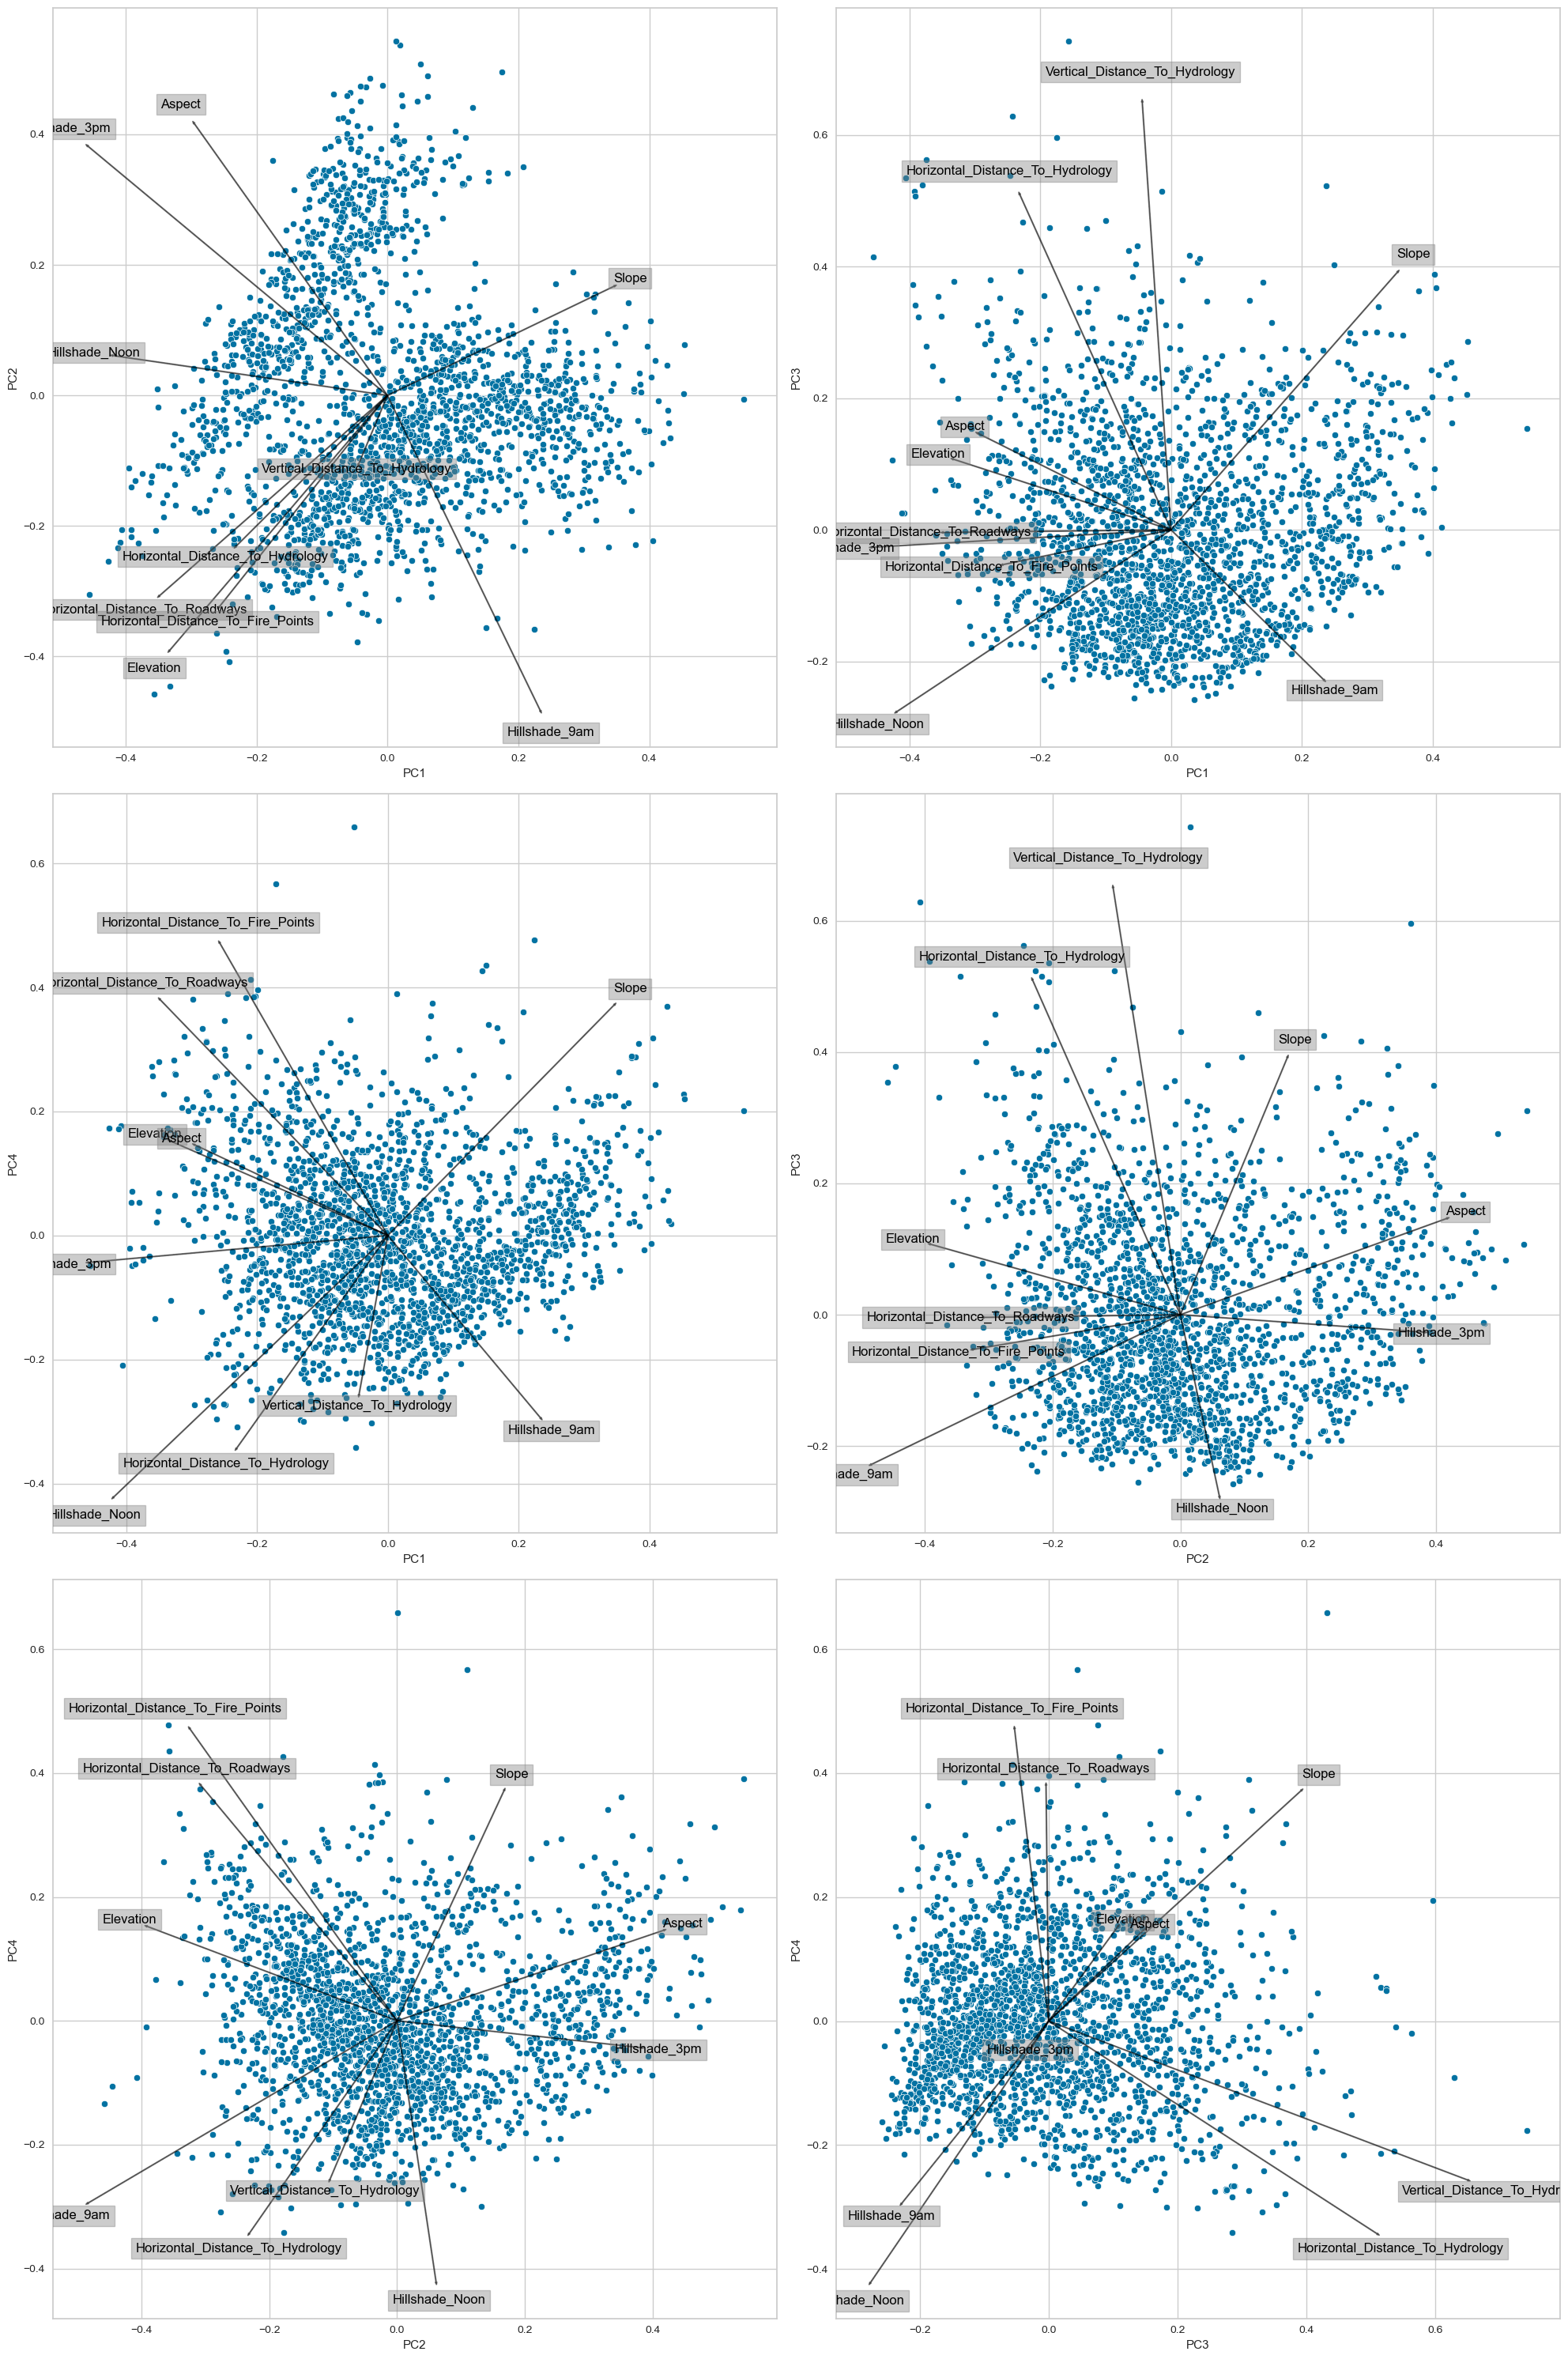

In [7]:
### Create biplots using function ###
fig, axs = plt.subplots(3, 2, figsize=(20, 30))

# PC1 and PC2
biplot(ax=axs[0,0], score=pcaFit[:,[0,1]], coeff=np.transpose(pca.components_[[0,1], :]), 
            pcLabels=[1,2], featureLabels=features, hue=None)

#PC1 and PC3
biplot(ax=axs[0,1], score=pcaFit[:,[0,2]], coeff=np.transpose(pca.components_[[0,2], :]),
       pcLabels=[1,3], featureLabels=features, hue=None)

#PC1 and PC4
biplot(ax=axs[1,0], score=pcaFit[:,[0,3]], coeff=np.transpose(pca.components_[[0,3], :]), 
       pcLabels=[1,4], featureLabels=features, hue=None)


#PC2 and PC3
biplot(ax=axs[1,1], score=pcaFit[:,[1,2]], coeff=np.transpose(pca.components_[[1,2], :]),
       pcLabels=[2,3], featureLabels=features, hue=None)


#PC2 and PC4
biplot(ax=axs[2,0], score=pcaFit[:,[1,3]], coeff=np.transpose(pca.components_[[1,3], :]), 
       pcLabels=[2,4], featureLabels=features, hue=None)


#PC3 and PC4
biplot(ax=axs[2,1], score=pcaFit[:,[2,3]], coeff=np.transpose(pca.components_[[2,3], :]), 
       pcLabels=[3,4], featureLabels=features, hue=None)
    
plt.tight_layout()
plt.show()

(*Note: If you receive any warnings, ignore them. It is just because we set the 'hue' parameter to 'None'.*)

##### Some insights from PCA and biplots
* In the first scatterplot (PC1-PC2) the data appears to be separated in two groups. The first group of forest plots has a large aspect score, as well as high hillshade scores at noon and 3 PM (top left). The second group has high hillshade score at 9 AM, while having low scores for aspect, hillshade noon and hillshade 3 PM (bottom right).
* Hillshade 9 AM is always strongly negatively correlated with aspect, as the arrows point in opposite directions.
* 'Horizontal distance to railroads' and horizontal distance to fire points' are always strongly postively correlated.

#### Use PCA for exploring labelled data
Luckily our dataset contains class labels! This is not always the case when performing PCA. We can use PCA and biplots to help explain the classes, which can be a very useful part of exploratory data analysis, even when planning to perform supervised learning.

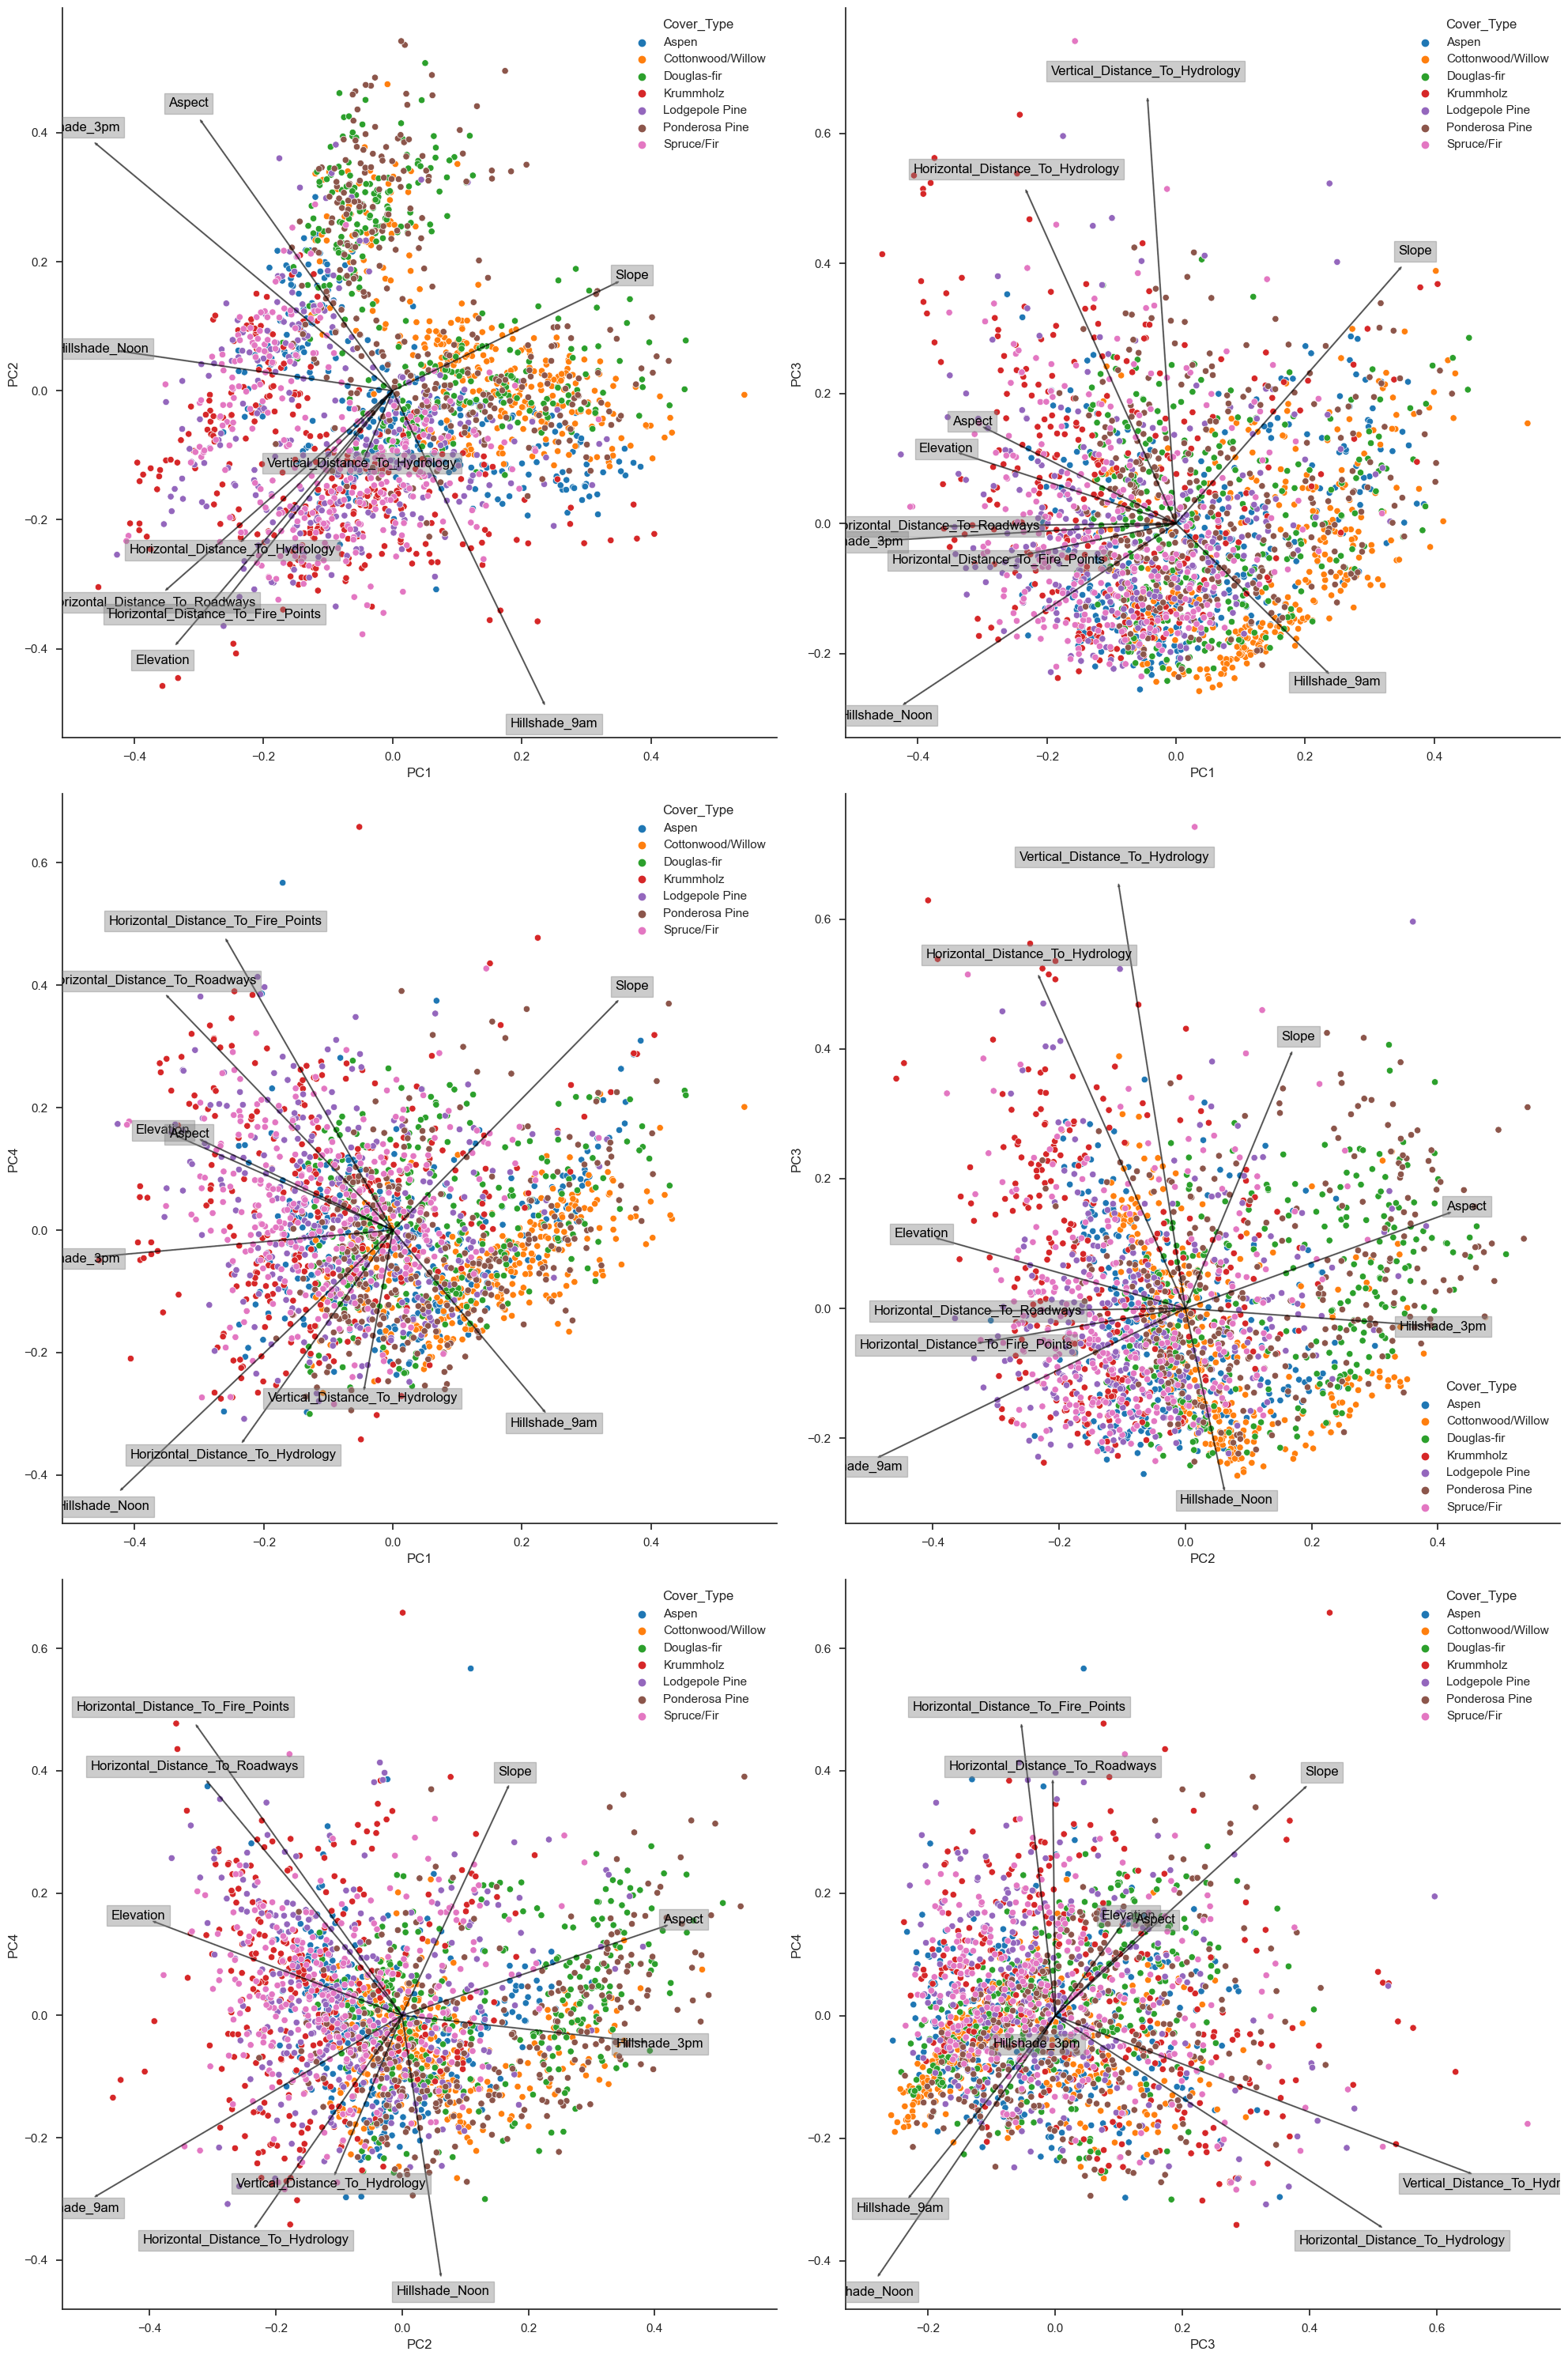

In [8]:
### Create biplots using function ###
fig, axs = plt.subplots(3, 2, figsize=(20, 30))

# PC1 and PC2
biplot(ax=axs[0,0], score=pcaFit[:,[0,1]], coeff=np.transpose(pca.components_[[0,1], :]), 
            pcLabels=[1,2], featureLabels=features, hue=df['Cover_Type'])

#PC1 and PC3
biplot(ax=axs[0,1], score=pcaFit[:,[0,2]], coeff=np.transpose(pca.components_[[0,2], :]),
       pcLabels=[1,3], featureLabels=features, hue=df['Cover_Type'])

#PC1 and PC4
biplot(ax=axs[1,0], score=pcaFit[:,[0,3]], coeff=np.transpose(pca.components_[[0,3], :]), 
       pcLabels=[1,4], featureLabels=features, hue=df['Cover_Type'])


#PC2 and PC3
biplot(ax=axs[1,1], score=pcaFit[:,[1,2]], coeff=np.transpose(pca.components_[[1,2], :]),
       pcLabels=[2,3], featureLabels=features, hue=df['Cover_Type'])


#PC2 and PC4
biplot(ax=axs[2,0], score=pcaFit[:,[1,3]], coeff=np.transpose(pca.components_[[1,3], :]), 
       pcLabels=[2,4], featureLabels=features, hue=df['Cover_Type'])


#PC3 and PC4
biplot(ax=axs[2,1], score=pcaFit[:,[2,3]], coeff=np.transpose(pca.components_[[2,3], :]), 
       pcLabels=[3,4], featureLabels=features, hue=df['Cover_Type'])
    
plt.tight_layout()
plt.show()

##### Some insights from PCA and biplots
* Based on the first plot (PC1-PC2), sample plots with Ponderosa Pine, Cottonwood/Willow, and Douglas Fir are strongly sloped while being at low elevation. 
* In the two plots 'PC1-PC3' and 'PC1-PC4', Cotton/Willow plots appear to be characterized by a high hillshade at 9 AM.
* Aspen plots cannot be separated from other plots using these ten variables.

## 3. Unsupervised clustering: K-means clustering

Unsupervised clustering is used to find patterns in datasets without prior knowledge about classes in the dataset. After clustering, the clusters can help explore the dataset in a structured way. 

'K-means' is one of the most popular unsupervised clustering algorithms. It is commonly used in consumer research and marketing. It allows discovery and investigation of target consumer groups based on survey data or data gathered by smartphone applications and credit card companies. Similarly, it could be applied to data related to natural resource management. For example, it can be used to better understand the types of people using provincial and national parks for recreation. Alternatively, it could be used to create groupings of plant species with similar habitat preferences based on a large field sample dataset including species, soil nutrient, soil moisture and topographic variables.

### 3.1 K-means clustering algorithm

The k-means devides a dataset into *n* homogeneous clusters, in which *n-clusters* is defined by the user. 

The clusters are defined following five steps:
1. First <em>n</em> seeds are placed. In the original k-means algorithm the seeds are placed random.
2. Euclidean distances are calculated between all data points and initIal seeds. Based on shortest distances, data points are assigned to the seeds.
3. Calculate the mean value of each cluster, becoming the cluster centroid.
4. The new cluster centroids replace the initial 'seeds' and are used to assign all data points to clusters, again using Euclidean distance.
5. Step 3-4 are repeated until clusters stop changing.

A visual explanation of the k-means algorithm is provided in Figure 7: 

<br>
<div style="text-align: center;">
<img src=https://i.imgur.com/uxuEeWu.jpg alt="image" width="650"/>
</div>
<br>
<div style="text-align: center;">
     <strong>Figure 7. A visual explanation of the k-means algorithm (o: Data point, X: Initial seed; O: Cluster mean)</strong>
    </div>
    <br>


### Example 2: Initial Seed Placement

The initial seed placement is a big factor influencing the quality of the final clusters. We will demonstrate that in the next example.

We are using a 'dummy' dataset with two variables:
* The number of nature-based trips a person made per year
* The total distance traveled.

We will group this data into four clusters. The first time we run k-means, we will pick random seeds once. The second, third and fourth time, we will pick a random number of seeds 10, 100 and 1000 times, respectively. The algorithm selects the best initial seeds based on inertia, in other words, the stability of the clusters' means throughout interations.

In [9]:
df = pd.read_csv('rec-survey-uk.csv')
df = df.loc[:,['trips1year', 'Distance']]
df.head()

,trips1year,Distance
0,5,10
1,1,60
2,1,44
3,1,20
4,1,15


In [10]:
### Create K-means function ###

def kMeansAddLabels(df, init, n_clusters, n_init, max_iter, random_state=3):
    ''' Function to perform k-means and add clusterIDs to the original DataFrame'''
    model =KMeans(init=init, n_clusters=n_clusters, n_init=n_init, max_iter=max_iter, random_state=3)
    model.fit(df)
    df['kClus_init'+str(n_init)+'_'+init] = model.labels_
    return(df)

In [11]:
### Run K-means with different numbers of times the algorithm will select different centroid seeds: 
### 1, 10, 100, and 1000 times

n_init_list = [1,10,100,1000] # n_init params
for i in n_init_list:
    df = kMeansAddLabels(df, init='random', n_clusters=4, n_init=i, max_iter=1, random_state=3) # run

C:\miniconda3\envs\gem530\lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\miniconda3\envs\gem530\lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\miniconda3\envs\gem530\lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\miniconda3\envs\gem530\lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Wi

(*Note: If you use KMeans clustering algorithm on Windows with the Intel Math Kernel Library (MKL), you might receive some warnings. You can ignore them for now.*)

In [12]:
df.head()

,trips1year,Distance,kClus_init1_random,kClus_init10_random,kClus_init100_random,kClus_init1000_random
0,5,10,2,2,3,3
1,1,60,1,3,0,2
2,1,44,1,3,0,2
3,1,20,2,2,3,3
4,1,15,2,2,3,3


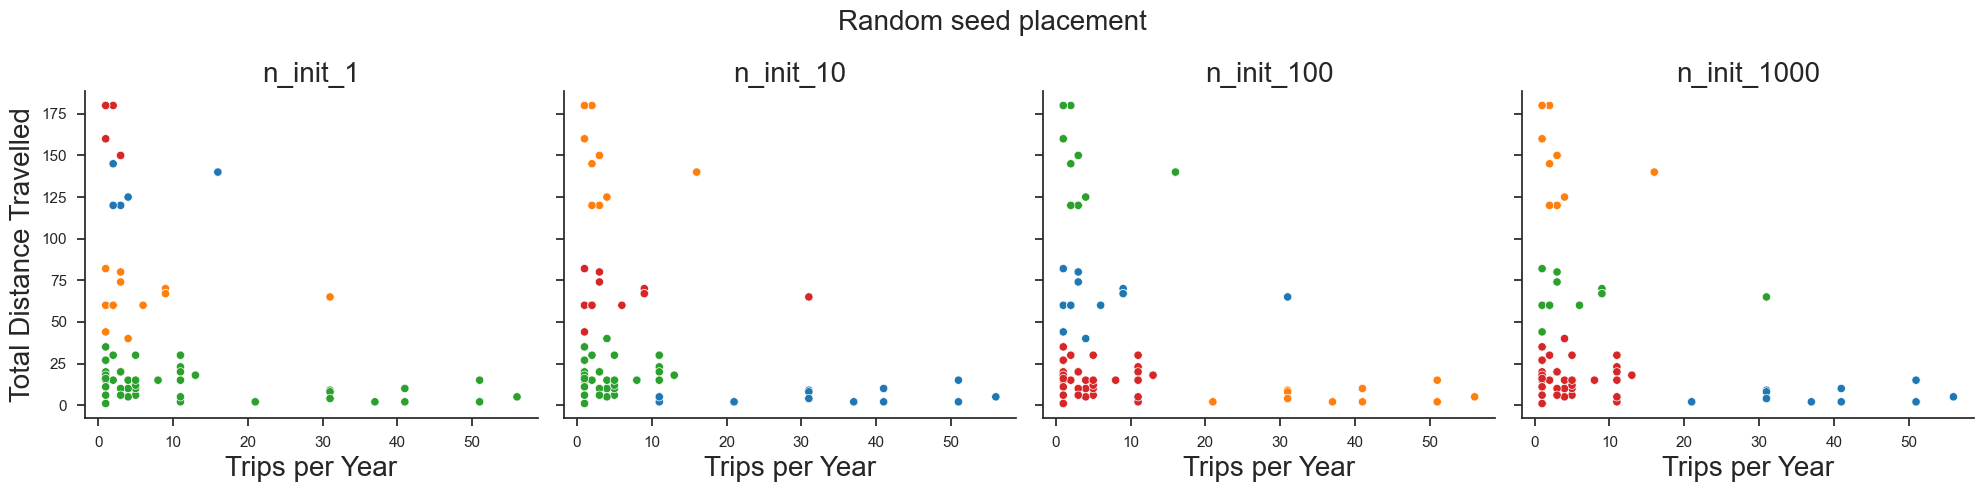

In [13]:
### Compare clusters of the four attempts using scatterplots ###
fig, ax = plt.subplots(nrows=1,ncols=4, figsize=(20,5), sharex=True, sharey=True) # Initiate grid for plotting with Pyplot
custom_params = {"axes.spines.right": False, "axes.spines.top": False} # Set theme Seaborn
sns.set_theme(style="ticks", rc=custom_params)

# Plot 1
f1 = sns.scatterplot(ax=ax[0], x='trips1year', y='Distance', hue='kClus_init1_random', data=df, palette="tab10", legend=False)
ax[0].set_title('n_init_1', fontsize=20)
ax[0].set_xlabel("Trips per Year", fontsize = 20)
ax[0].set_ylabel("Total Distance Travelled", fontsize = 20)
# Plot 2
f2 = sns.scatterplot(ax=ax[1], x='trips1year', y='Distance', hue='kClus_init10_random', data=df, palette="tab10", legend=False)
ax[1].set_title('n_init_10', fontsize=20)
ax[1].set_xlabel("Trips per Year", fontsize = 20)
ax[1].set_ylabel("Total Distance Travelled", fontsize = 20)
# Plot 3
f3 = sns.scatterplot(ax=ax[2], x='trips1year', y='Distance', hue='kClus_init100_random', data=df, palette="tab10", legend=False)
ax[2].set_title('n_init_100', fontsize=20)
ax[2].set_xlabel("Trips per Year", fontsize = 20)
ax[2].set_ylabel("Total Distance Travelled", fontsize = 20)
# Plot 4
f4 = sns.scatterplot(ax=ax[3], x='trips1year', y='Distance', hue='kClus_init1000_random', data=df, palette="tab10", legend=False)
ax[3].set_title('n_init_1000', fontsize=20)
ax[3].set_xlabel("Trips per Year", fontsize = 20)
ax[3].set_ylabel("Total Distance Travelled", fontsize = 20)

fig.suptitle('Random seed placement', fontsize=20) 
fig.tight_layout()

The clusters changed a lot! Specifically, selecting the intial seeds just once versus selecting the 'best' seeds out of ten attempts makes a large difference. From the second attempts (n_init: 10), the clusters are similar to how we would split the points into clusters visually. There are some minor improvements when randomly selecting clusters a 100 times.

An alternative method for centroid selection, known as k-means++, offers a smarter approach. In this approach, the first centroid seed is chosen randomly, while the subsequent centroid seeds are strategically selected based on the maximum squared distance. This technique aims to position centroids as far apart from each other as possible, enhancing the initialization process for the k-means algorithm.

So let's run the previous experiment again with K-means++:

C:\miniconda3\envs\gem530\lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\miniconda3\envs\gem530\lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\miniconda3\envs\gem530\lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\miniconda3\envs\gem530\lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Wi

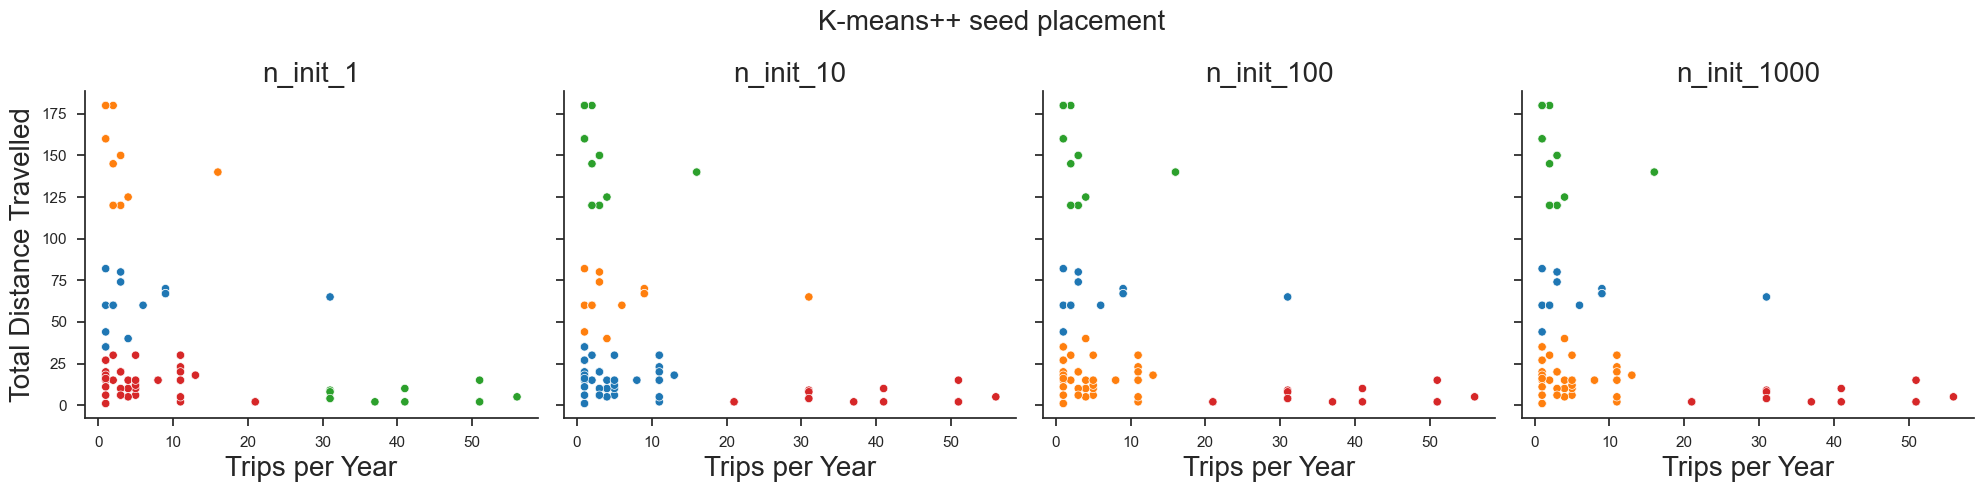

In [14]:
### Run K-means with different numbers of iterations will result in the selection of different centroid seeds: 
### 1, 10, 100, and 1000 times

n_init_list = [1,10,100,1000] # n_init params
for i in n_init_list:
    df = kMeansAddLabels(df, init='k-means++', n_clusters=4, n_init=i, max_iter=1, random_state=3) # run
    
### Compare clusters of the four attempts using scatterplots ###
fig, ax = plt.subplots(nrows=1,ncols=4, figsize=(20,5), sharex=True, sharey=True) # Initiate grid for plotting with Pyplot
custom_params = {"axes.spines.right": False, "axes.spines.top": False} # Set theme Seaborn
sns.set_theme(style="ticks", rc=custom_params)


# Plot 1
f1 = sns.scatterplot(ax=ax[0], x='trips1year', y='Distance', hue='kClus_init1_k-means++', data=df, palette="tab10", legend=False)
ax[0].set_title('n_init_1', fontsize=20)
ax[0].set_xlabel("Trips per Year", fontsize = 20)
ax[0].set_ylabel("Total Distance Travelled", fontsize = 20)
# Plot 2
f2 = sns.scatterplot(ax=ax[1], x='trips1year', y='Distance', hue='kClus_init10_k-means++', data=df, palette="tab10", legend=False)
ax[1].set_title('n_init_10', fontsize=20)
ax[1].set_xlabel("Trips per Year", fontsize = 20)
ax[1].set_ylabel("Total Distance Travelled", fontsize = 20)
# Plot 3
f3 = sns.scatterplot(ax=ax[2], x='trips1year', y='Distance', hue='kClus_init100_k-means++', data=df, palette="tab10", legend=False)
ax[2].set_title('n_init_100', fontsize=20)
ax[2].set_xlabel("Trips per Year", fontsize = 20)
ax[2].set_ylabel("Total Distance Travelled", fontsize = 20)
# Plot 4
f4 = sns.scatterplot(ax=ax[3], x='trips1year', y='Distance', hue='kClus_init1000_k-means++', data=df, palette="tab10", legend=False)
ax[3].set_title('n_init_1000', fontsize=20)
ax[3].set_xlabel("Trips per Year", fontsize = 20)
ax[3].set_ylabel("Total Distance Travelled", fontsize = 20)

fig.suptitle('K-means++ seed placement', fontsize=20) 
fig.tight_layout()

The clusters look quite good when the initial seeds are just placed once! After repeating the seed placement 10, 100, or 1000 times, the clusters show only minimal changes.

#### The effect of scaling on k-means

Like many other machine learning techniques k-means benefits from scaling, and particularly 'standardization'. Thus the use of sklearn's `StandardScaler` should result in better results than using `MinMaxScaler` and no scaling. 

With standardization, variables with different ranges and variance are scaled to have the same range and variance. If all variables have the same mean and theoretical data range, which is not necessarily the same as the range of the sample dataset, than you do not need to standardize your variables. Some examples are longitude (-180 to 180 degrees) and latitude (-90 to 90 degrees), as well as light reflectance (0 - 100% light reflected).

In [15]:
# 1. Create a new DataFrame with MinMax scaled values
features = ['trips1year', 'Distance']

minMaxScaler = MinMaxScaler()
minMaxScaler.fit(df.loc[:,features])
dfMinMax = pd.DataFrame(minMaxScaler.transform(df.loc[:,features]), columns=features) # scale and convert np.array back to pandas DataFrame again

dfMinMax.head()

,trips1year,Distance
0,0.072727,0.050279
1,0.000000,0.329609
2,0.000000,0.240223
3,0.000000,0.106145
4,0.000000,0.078212


In [16]:
# 2. Create a new DataFrame with Standardized values
standScaler = StandardScaler()
standScaler.fit(df.loc[:,features])
dfStandScale = pd.DataFrame(standScaler.transform(df.loc[:,features]), columns=features) # scale and convert np.array back to pandas DataFrame again

dfStandScale.head()

,trips1year,Distance
0,-0.362791,-0.665423
1,-0.664419,0.282773
2,-0.664419,-0.020650
3,-0.664419,-0.475783
4,-0.664419,-0.570603


In [17]:
## Run K-means++ on the DataFrames with default parameters

# 1. For non-scaled values
dfNonScale = kMeansAddLabels(df.loc[:,features], init='k-means++', n_clusters=3, n_init=10, max_iter=300, random_state=3) # run

# 2. For MinMax scaled values
dfMinMax = kMeansAddLabels(dfMinMax, init='k-means++', n_clusters=3, n_init=10, max_iter=300, random_state=3) # run

# 3. For Standardized values
dfStandScale = kMeansAddLabels(dfStandScale, init='k-means++', n_clusters=3, n_init=10, max_iter=300, random_state=3) # run

C:\miniconda3\envs\gem530\lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\miniconda3\envs\gem530\lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\miniconda3\envs\gem530\lib\site-packages\sklearn\cluster\_kmeans.py:1382: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


(Note: If you use KMeans clustering algorithm on Windows with the Intel Math Kernel Library (MKL), you might receive some warnings. You can ignore them for now.)

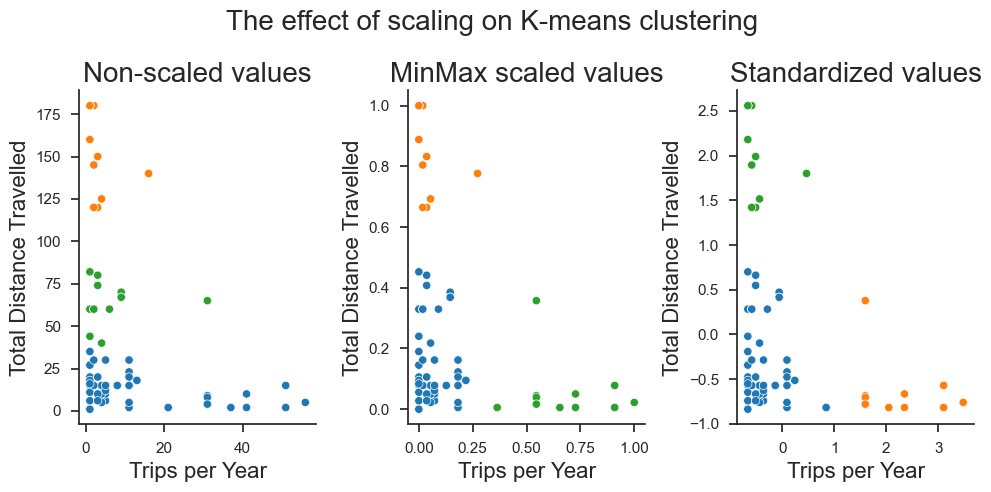

In [18]:

### Compare clusters using scatterplots ###
fig, ax = plt.subplots(nrows=1,ncols=3, figsize=(10,5), sharex=False, sharey=False) # Initiate grid for plotting with Pyplot
custom_params = {"axes.spines.right": False, "axes.spines.top": False} # Set theme Seaborn
sns.set_theme(style="ticks", rc=custom_params)

# Plot 1
f1 = sns.scatterplot(ax=ax[0], x='trips1year', y='Distance', hue='kClus_init10_k-means++', data=dfNonScale, palette="tab10", legend=False)
ax[0].set_title('Non-scaled values', fontsize=20)
ax[0].set_xlabel("Trips per Year", fontsize = 16)
ax[0].set_ylabel("Total Distance Travelled", fontsize = 16)
# Plot 2
f1 = sns.scatterplot(ax=ax[1], x='trips1year', y='Distance', hue='kClus_init10_k-means++', data=dfMinMax, palette="tab10", legend=False)
ax[1].set_title('MinMax scaled values', fontsize=20)
ax[1].set_xlabel("Trips per Year", fontsize = 16)
ax[1].set_ylabel("Total Distance Travelled", fontsize = 16)
# Plot 3
f2 = sns.scatterplot(ax=ax[2], x='trips1year', y='Distance', hue='kClus_init10_k-means++', data=dfStandScale, palette="tab10", legend=False)
ax[2].set_title('Standardized values', fontsize=20)
ax[2].set_xlabel("Trips per Year", fontsize = 16)
ax[2].set_ylabel("Total Distance Travelled", fontsize = 16)
# Plot 3

fig.suptitle('The effect of scaling on K-means clustering', fontsize=20)
fig.tight_layout()

In this case, clusters following 'standardization' changed compared to the no scaling. It is challenging to determine which clustering result is better. Based on the first plot we can see that only the 'total distance traveled' variable determined the clusters on non-scaled data. After standardization, both predictor variables determined the clusters. 

### Example 3: Defining the number of clusters: <em>k</em>

#### Data set
This time we will work with some real survey data. Birdwatchers, part of a wide range of bird related organizations and Facebook groups, were sampled through a questionaire (n = 2766; 50.5% men) in Germany, 2020. They were asked to rate their birding skills, behaviour (for example, the number of times they spent birding), as well as the importance to lifestyle and social life. The data comes from the following paper: </br> 

* Randler, Christoph. 2021. "An Analysis of Heterogeneity in German Speaking Birdwatchers Reveals Three Distinct Clusters and Gender Differences" Birds 2, no. 3: 250-260. https://doi.org/10.3390/birds2030018

A summary of the variables in the dataset:
1. Demographics:
    * Age in years (`Alter01_A`)
    * Gender including male (1.0) and female (2.0)
2. Skills:
    *  Transformed variable based on multiple inputs including (`ZSKILL_COMP`): 'the number of species a person is able to identify without a field guide by appearance and by song without a field guide' as well as a 'self-assessed knowledge score'.
3. Behavior:
    * Transformed variable based on multiple inputs including (`ZBEHAVIOUR`): 'the number of birding trips taken last year (at least 2 km away from home)', 'number of days spent for birding last year', 'number of bird species on lifelist', 'number of bird books owned', 'replacement value of the total equipment', and 'number of species on a national list'.
4. Involvement:
    * Level of attraction (`ZATTRACTION`)
    * Centrality to lifestyle (`ZCENTRALITY`)
    * Social bonding (`ZSOCIAL_BONDING`)

#### Define K-clusters

How do we define the number of clusters? To answer this question, we need to understand what makes good clustering. The goal is to minimize the variance within each cluster, and ideally, data points should not overlap across clusters. Simultaneously, we aim to keep the total number of clusters as small as possible for ease of interpretation. A common approach is to use the Elbow method. This method involves plotting an evaluation metric (y) against the number of clusters (x) on a line graph. The line typically resembles an elbow, and the optimal number of clusters is often identified at the point of the sharpest turn.

Two key metrics used in the evaluation of clustering are:
* The sum of squared error (SSE)
* Silhouette Score

**SSE** is defined as the sum of the squared distance between centroid and each member of the cluster. The smaller this value is, the more compact the clusters are. This value needs to be as small as possible, however, there is a point where SSE does not decrease significantly when increasing k.

The **silhouette score** ranges is calculated based on two metrics calculated for all points: (1) intra-cluster distance and (2) nearest-cluster distance. Intra-cluster distance is the mean distance between each data point and all other points in the cluster. Nearest-cluster is the mean distance between each data point and all other data points of the next nearest cluster. The silhouette score ranges from -1 to 1, where 1 indicates compact and well-seperated clusters.

In [19]:
# Read
df = pd.read_csv('German_Birdwatchers_OSF.csv')

# Replace 1 and 2 by 'gender' 
df['gender'] = np.where(df['gender']==1.0, 'male', 'female')

# Check
df.head()

,Unnamed: 0,Alter01_A,gender,ZSKILL_COMP,ZBEHAVIOUR,ZPERSON_COMM,ZBEHAV_COMM,ZATTRACTION,ZCENTRALITY,ZSOCIAL_BONDING,ZIDENTITY,QCL_1
0,1,47.0,male,0.022858,1.377752,0.791095,-0.524031,0.577703,-1.376459,-0.761405,-1.645494,2
1,2,39.0,female,-0.793128,-0.925507,0.076941,-0.524031,-2.243709,0.464292,0.419114,0.847533,2
2,3,49.0,male,-1.193159,1.985391,-0.637214,-0.524031,-0.631474,-0.456084,-0.367899,-1.645494,2
3,4,58.0,female,-0.379212,-0.897305,-0.280136,-1.014877,1.383821,-1.376459,-0.761405,-1.645494,2
4,5,44.0,male,2.829722,0.213962,0.076941,-0.524031,-0.228415,-0.456084,-0.367899,0.016524,1


In [20]:
# Isolate variables used for k-means
dfSelect = df.loc[:,['ZSKILL_COMP', 'ZBEHAVIOUR', 'ZATTRACTION', 'ZCENTRALITY', 'ZSOCIAL_BONDING']] # 'Predictor' variables only
dfSelect.head()

,ZSKILL_COMP,ZBEHAVIOUR,ZATTRACTION,ZCENTRALITY,ZSOCIAL_BONDING
0,0.022858,1.377752,0.577703,-1.376459,-0.761405
1,-0.793128,-0.925507,-2.243709,0.464292,0.419114
2,-1.193159,1.985391,-0.631474,-0.456084,-0.367899
3,-0.379212,-0.897305,1.383821,-1.376459,-0.761405
4,2.829722,0.213962,-0.228415,-0.456084,-0.367899


In [21]:
# Standardize values
standScaler = StandardScaler()
standScaler.fit(dfSelect)
dfStandScale = pd.DataFrame(standScaler.transform(dfSelect), columns=dfSelect.columns) # scale and convert np.array back to pandas DataFrame again

dfStandScale.head()

,ZSKILL_COMP,ZBEHAVIOUR,ZATTRACTION,ZCENTRALITY,ZSOCIAL_BONDING
0,0.022862,1.378001,0.577808,-1.376708,-0.761543
1,-0.793271,-0.925674,-2.244115,0.464376,0.419190
2,-1.193375,1.985750,-0.631588,-0.456166,-0.367965
3,-0.379280,-0.897468,1.384071,-1.376708,-0.761543
4,2.830234,0.214001,-0.228456,-0.456166,-0.367965


Text(0, 0.5, 'SSE score')

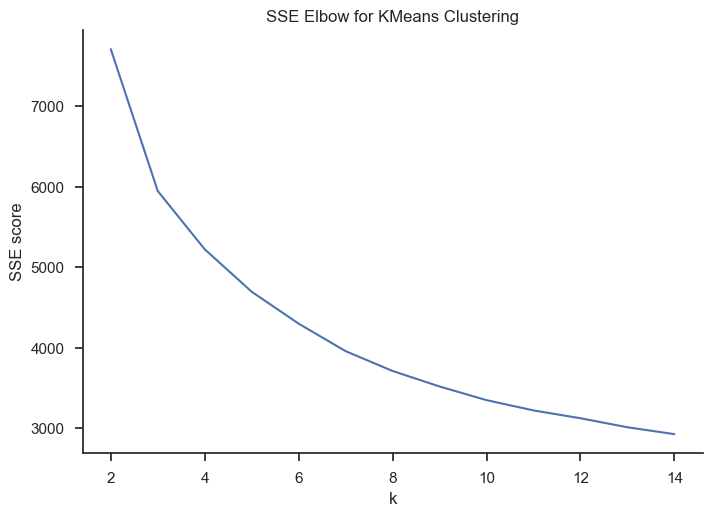

In [22]:
### SSE Elbow: Run KMeans with Scikit-learn and plot with Seaborn ###    
Sum_of_squared_distances = [] # Empty list for SSE outputs
K = range(2,15) # Run K means with n between 1 and 15

for k in K: 
    km =KMeans(n_clusters=k,n_init=10) # Initiate model
    km =km.fit(dfStandScale) # Fit model
    Sum_of_squared_distances.append(km.inertia_) # Add SSE to list

### Plotting ###    
f = sns.lineplot(x=K, y=Sum_of_squared_distances)
f.set_title('SSE Elbow for KMeans Clustering', fontsize=12)
f.set_xlabel("k", fontsize = 12)
f.set_ylabel("SSE score", fontsize = 12)

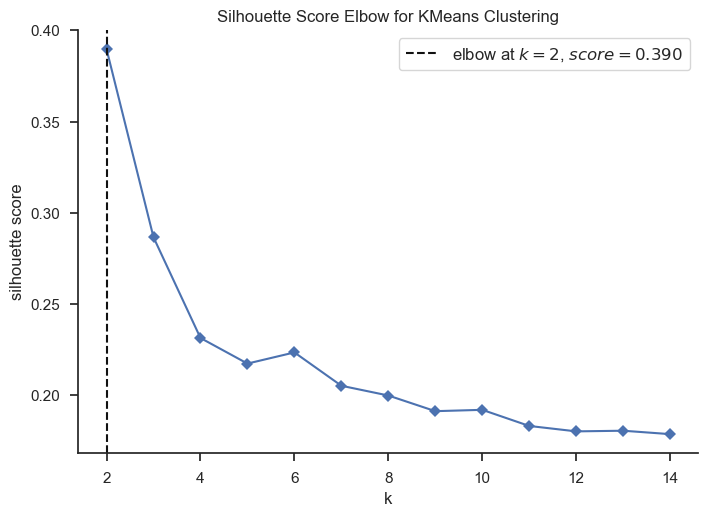

<Axes: title={'center': 'Silhouette Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='silhouette score'>

In [23]:
### Silhouette Score elbow: Run KMeans and plot with KElbowVisualizer ###  
model = KMeans(random_state=123, n_init=10) 
visualizer = KElbowVisualizer(model, k=(2,15), metric='silhouette', timings=False)

visualizer.fit(dfStandScale)    
visualizer.poof()

In the first plot (SSE), the Elbow is at k=3, while in the second plot (Silhouette Score), the Silhouette Score is the most between k=2 and k=4. 

For further analysis, we will select k=3.

#### Implementing and assessing K-means

We will apply k-means to this dataset using 3 clusters. 

In [24]:
### Run KMeans with Scikit-learn
model = KMeans(n_clusters=3,  random_state=123,  n_init=10)
model.fit(dfStandScale)

# Add cluster' labels to original DataFrame
df['kClus'] = model.labels_

We will explore the clusters using various visualizations previously introduced in the descriptive data analysis lecture.

Text(0, 0.5, 'Age')

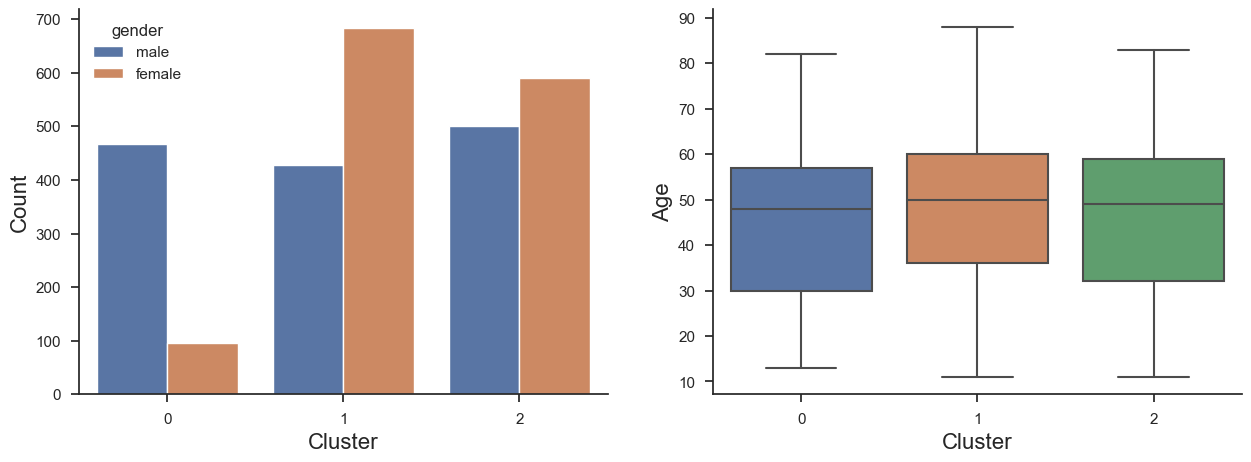

In [25]:
# Initiate grid for plotting with Pyplot
fig, ax = plt.subplots(nrows=1,ncols=2, figsize=(15,5))

# Set theme Seaborn
custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params)

# Left plot
f1 = sns.countplot(ax=ax[0], x="kClus", hue="gender", data=df)
ax[0].set_xlabel("Cluster", fontsize = 16)
ax[0].set_ylabel("Count", fontsize = 16)

# Right plot
f2 = sns.boxplot(ax=ax[1], x="kClus", y="Alter01_A", data=df)
ax[1].set_xlabel("Cluster", fontsize = 16)
ax[1].set_ylabel("Age", fontsize = 16)


##### Some insights:
* Age distribution of every birdwatchers' cluster is similar, with a mean age close to 50 for every group. 
* Cluster 0 is largely dominated by men, cluster 1 is dominated by woman, and cluster 2 has a gender ratio close to 1:1.

Now let's look at the distribution of the questionaire metrics accross the clusters. We will create a boxplot with nested grouping using 'Seaborn'. This requires us to convert the DataFrame to a 'long' format first.

In [26]:
# Convert DataFrame from wide to long format for plotting
dfLong = pd.melt(df, id_vars=['Unnamed: 0', 'Alter01_A', 'gender', 'kClus'], value_vars=['ZSKILL_COMP', 'ZBEHAVIOUR', 'ZATTRACTION', 'ZCENTRALITY', 'ZSOCIAL_BONDING'])

Text(0, 0.5, 'Questionaire Metric Score')

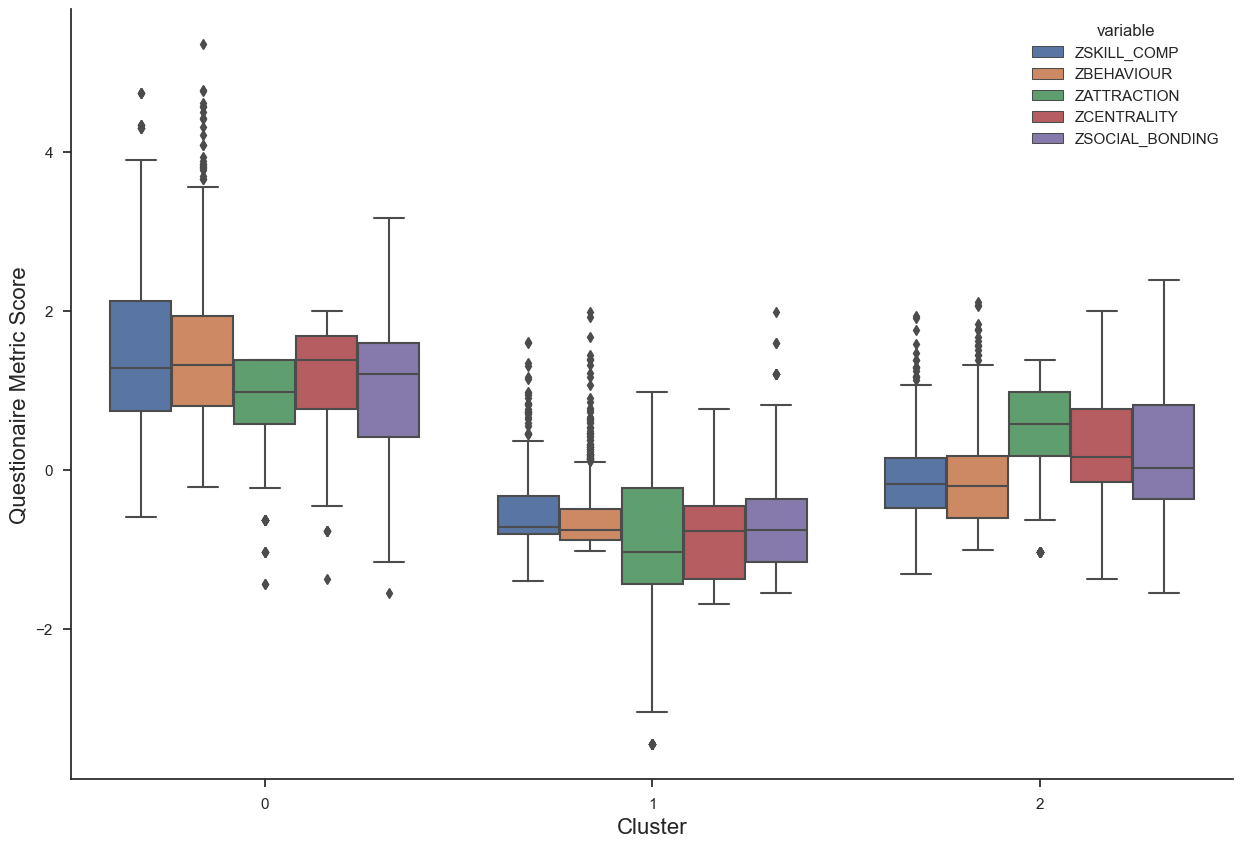

In [27]:
# Initiate grid for plotting with Pyplot
fig, ax = plt.subplots(nrows=1,ncols=1, figsize=(15,10))

# Set theme Seaborn
custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params)

f1 = sns.boxplot(ax=ax, x="kClus", y="value", data=dfLong, hue="variable")
ax.set_xlabel("Cluster", fontsize = 16)
ax.set_ylabel("Questionaire Metric Score", fontsize = 16)

Because of standardizing the data before clustering distribution of variables have similar scale and centers are around zero but they were separated for these three clusters. Hence, the mean is not around zero but close for those variables. By visualizing the standardized "Questionnaire Metric Score" within each cluster, we can see how each cluster's metric scores are distributed around the mean (0) and assess their variability (standard deviation of 1). This can provide insights into how well the clustering method groups data points with similar standardized scores.

Within cluster 0 birders are most skilled, go birdwatching most often, and highly value their hobby. Within cluster 1 the scores are lowest.

The metrics show that the clusters can be labelled as:
 * 0 = Advanced
 * 1 = Beginner
 * 2 = Intermediate
 
A scatterplot can help us assess the quality of our clusters. As we do have more than two variables this time we need to use a data reduction technique, and yes we can use **PCA**!

In [28]:
### Perform PCA ###
# 1. Initiate PCA model
pca = PCA(n_components=2) 
# 2. Fit the standardized values
pca_out = PCA().fit(dfStandScale) # Fit the standardized values
# 3. Get Principal component loadings
loadings = pca_out.components_ # Get Principal component loadings
# 4. Get Principal component values
pca_scores = PCA().fit_transform(dfStandScale) # Get Principal component values



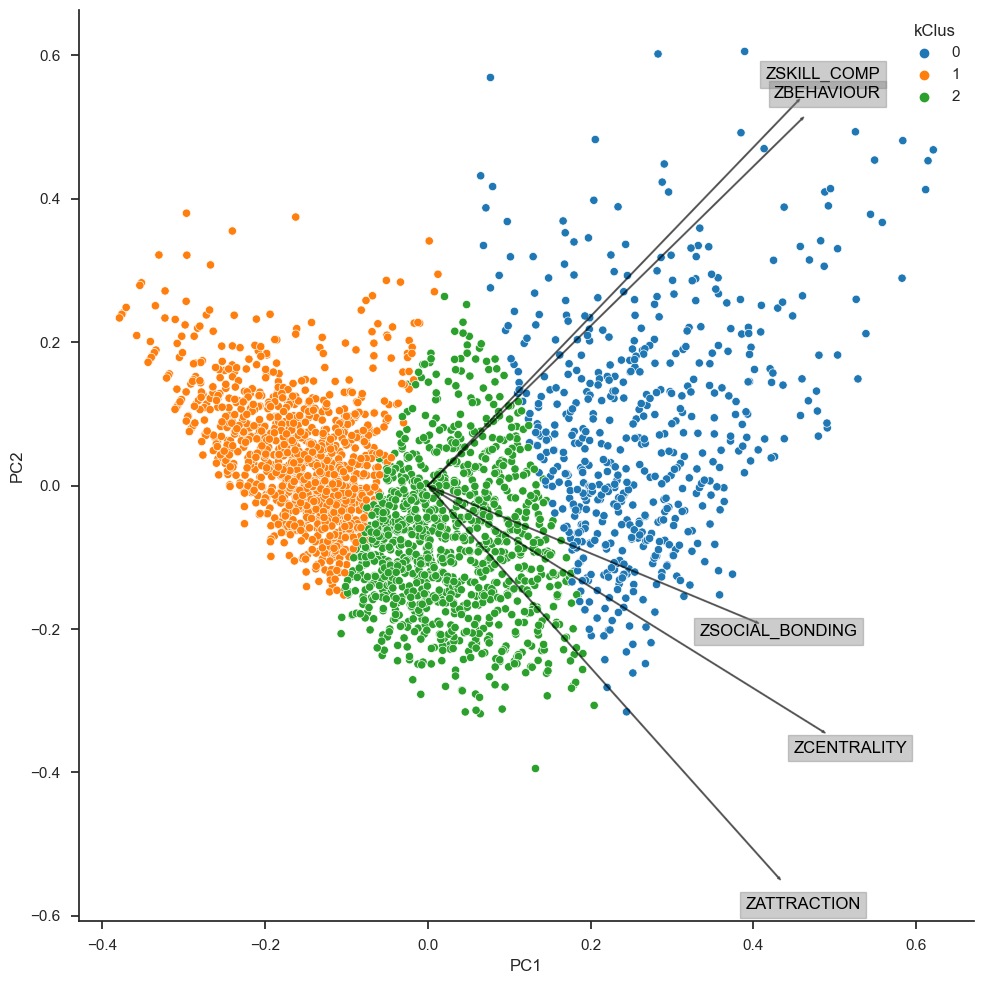

In [29]:
### Let's plot a biplot using the function given in the first section. The colors represent the k-means clusters
fig, axs = plt.subplots(1, 1, figsize=(10, 10))

# Run custom biplot function
biplot(ax=axs, score=pca_scores[:,0:2], coeff=np.transpose(loadings[0:2, :]), pcLabels=[1,2], featureLabels=list(dfSelect.columns), hue=df['kClus'])

plt.tight_layout()
plt.show()

There is no overlap between the clusters, which is good. However, the clusters are not as compact and nicely seperated as in the previous examples. 

The biplot can help explain the three clusters similarly as the boxplots. Additionally, the biplot shows us that `Zskill_comp` and `Zbehaviour` are highly correlated.

**Note:  If you are having trouble applying K-means to your dataset due to size (Big data), try the Mini-batch-K-Means which is optimized for large datasets. More information can be found here: https://scikit-learn.org/stable/modules/clustering.html#mini-batch-k-means**

## 4. Hierarchical clustering

### 4.1. Introduction to hierarchical clustering
Hierarchical clustering uses a bottum-up approach, where each data point is intially its own cluster. Similar clusters are then successively merged together. This allows you to visualize the relationships between all clusters, which can be useful for understanding your dataset. However, hierarchical clustering demands a lot of computation for large datasets. We will explain the common hierarchical clustering algorithms and main visualization techniques.

### 4.2. Statistical metrics and choices related to hierarchical clustering

Data observations are merged when they are considered close, but what defines 'closeness'? In K-means clustering, clusters' means are iteratively adjusted to minimize the sum of squared distances between means and observations within the same cluster. But in hierarchical clustering, there are four methods to determine proximity: Single-Linkage, Average Linkage, Complete Linkage, and Ward. Each of these linkage criteria plays a role in deciding when observations should be merged.

* **Hierarchical clustering - Single linkage:** For hierarchical clustering with single linkage, clusters are merged when they are closest based on pair-wise Euclidean distance. Initially, all observations are individual clusters. This method could result in long and narrow clusters.
* **Hierarchical clustering - Average linkage:** Average linkage minimizes the average distance between all pairs of clusters. Again, initially the observations form individual clusters.
* **Hierarchical clustering - Maximum or complete linkage:** Maximum or complete linkage minimizes the maximum distance between observations of pairs of clusters.
* **Hierarchical clustering - Ward:** Ward minimizes the increase in the sum of squared distances for a cluster. It is a variance-minimizing approach and in this sense is similar to the k-means objective function but is handled through an agglomerative hierarchical process.


(For more information: https://scikit-learn.org/stable/modules/clustering.html#hierarchical-clustering)

### Example 4: Hierarchical Clustering

For this example, we are using the same standardized values as in the previous example:

In [30]:
# setting distance_threshold=0 ensures we compute the full tree.
# linkage options: ‘ward’, ‘complete’, ‘average’, ‘single’
# n_clusters: set number of clusters that we would like to seperate.
# Note that n_clusters does not influence the hierarchcial relationships!
model = AgglomerativeClustering(linkage='ward', distance_threshold=0, n_clusters=None)
model = model.fit(dfStandScale)

The linkage criterion that is used here is the Ward linkage method. Setting the distance threshold to 0 ensures that the full hierarchical tree is computed, capturing all possible clusters. The number of clusters is set to None, meaning that the algorithm will not enforce a specific number of clusters. The hierarchical structure will be built, and the number of clusters can be determined later based on the tree structure or by cutting the tree at a specific height.

#### Assessing clustering results

In [31]:
             
def plot_dendrogram(model, **kwargs):
    '''Create linkage matrix and then plot the dendrogram
    Function (Source: https://scikit-learn.org/stable/auto_examples/cluster/plot_agglomerative_dendrogram.html#plot-hierarchical-clustering-dendrogram)'''
    
    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    # Plot the corresponding dendrogram
    dendrogram(linkage_matrix, **kwargs)

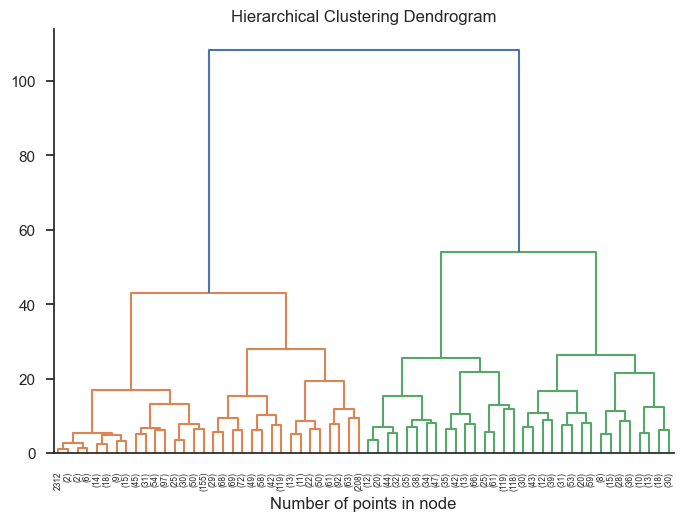

In [32]:
plt.title("Hierarchical Clustering Dendrogram")
# plot the top three levels of the dendrogram
plot_dendrogram(model, truncate_mode="level", p=5)
plt.xlabel("Number of points in node")
plt.show()

This is a **dendogram** of the dataset. We need to define where we would like to split the dendogram in order to create final clusters. This is an advantage over k-means, as we can define the number of clusters based on the dendogram and do not have to use an elbow method. The dendogram shows the dataset naturally groups into four clusters. However, let's split the dendogram into three clusters for now, so we can compare results with our previously computed k-means clusters. The dendogram will be split between ~44 and 50.

In [33]:
# setting distance_threshold=0 ensures we compute the full tree.
# linkage options: ‘ward’, ‘complete’, ‘average’, ‘single’
# n_clusters: set number of clusters that we would like to seperate.
# Note that n_clusters does not influence the hierarchcial relationships!
model = AgglomerativeClustering(linkage='ward', compute_distances=True, n_clusters=3)
model = model.fit(dfStandScale)

In [34]:
df['hClus'] = model.labels_

Text(0, 0.5, 'Age')

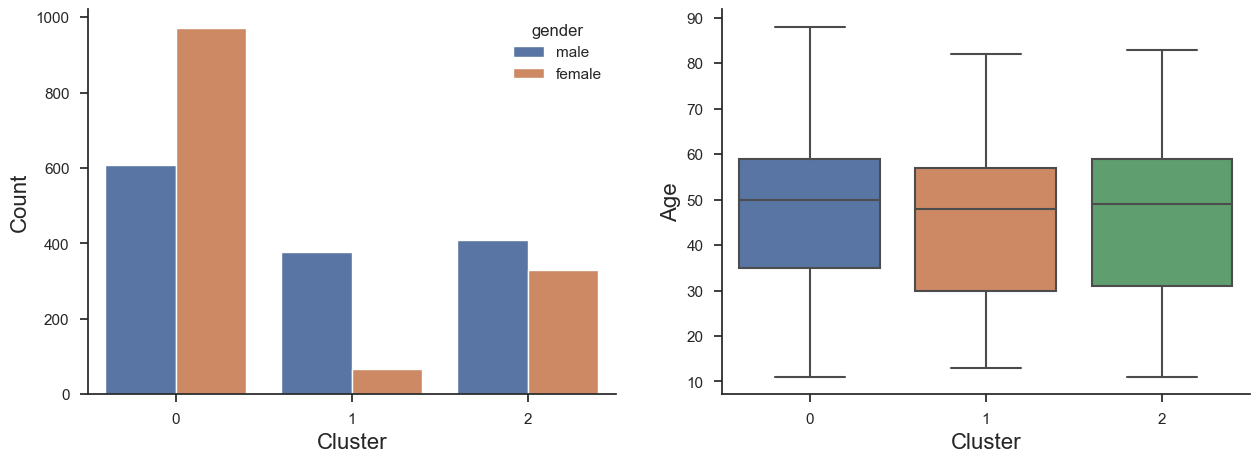

In [35]:
# Initiate grid for plotting with Pyplot
fig, ax = plt.subplots(nrows=1,ncols=2, figsize=(15,5))

# Set theme Seaborn
custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params)

# Left plot
f1 = sns.countplot(ax=ax[0], x="hClus", hue="gender", data=df)
ax[0].set_xlabel("Cluster", fontsize = 16)
ax[0].set_ylabel("Count", fontsize = 16)

# Right plot
f2 = sns.boxplot(ax=ax[1], x="hClus", y="Alter01_A", data=df)
ax[1].set_xlabel("Cluster", fontsize = 16)
ax[1].set_ylabel("Age", fontsize = 16)

In [36]:
# Convert DataFrame from wide to long format for plotting
dfLong = pd.melt(df, id_vars=['Unnamed: 0', 'Alter01_A', 'gender', 'kClus', 'hClus'], value_vars=['ZSKILL_COMP', 'ZBEHAVIOUR', 'ZATTRACTION', 'ZCENTRALITY', 'ZSOCIAL_BONDING'])

Text(0, 0.5, 'Questionaire Metric Score')

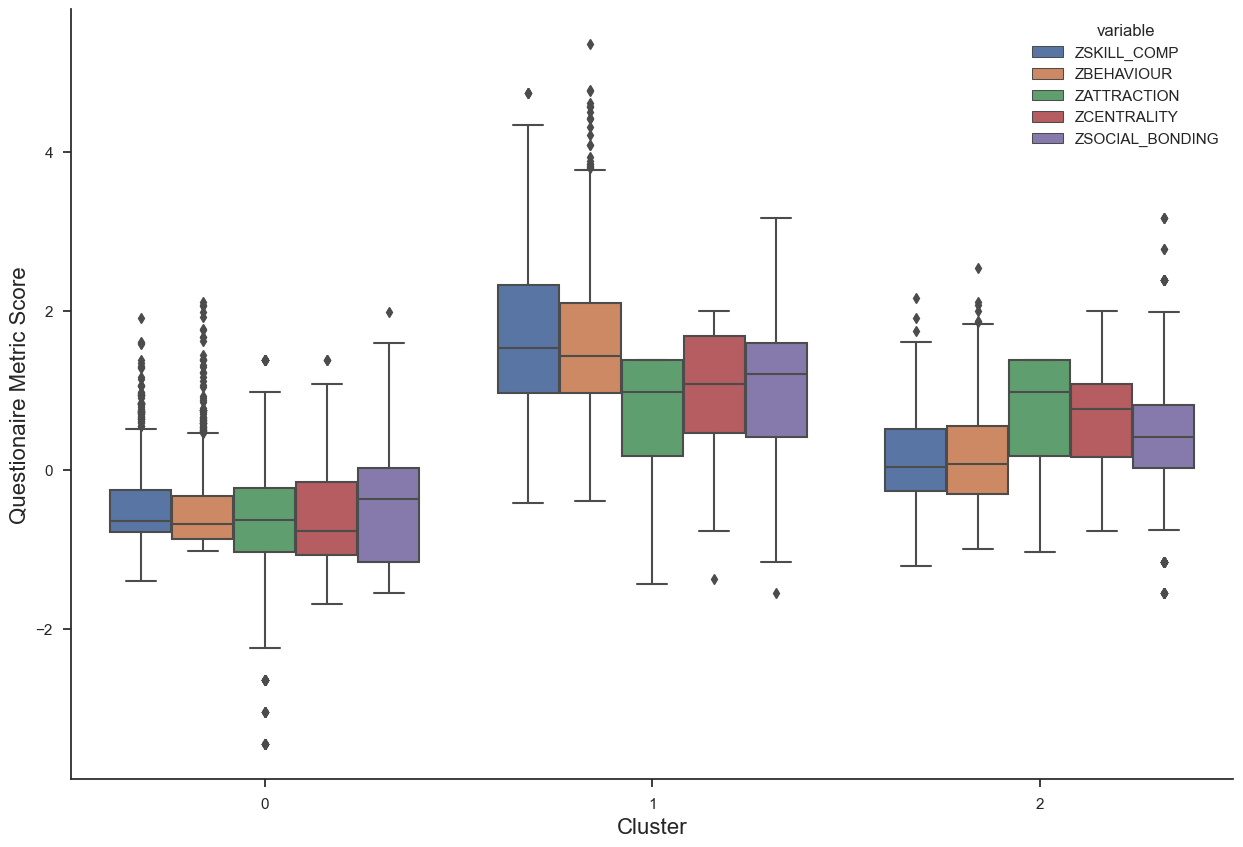

In [37]:
# Initiate grid for plotting with Pyplot
fig, ax = plt.subplots(nrows=1,ncols=1, figsize=(15,10))

# Set theme Seaborn
custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params)

f1 = sns.boxplot(ax=ax, x="hClus", y="value", data=dfLong, hue="variable")
ax.set_xlabel("Cluster", fontsize = 16)
ax.set_ylabel("Questionaire Metric Score", fontsize = 16)

The clusters closely resemble those from k-means, with only the labels for clusters 0 and 1 swapped.

#### Adjusting the number of clusters based on the dendogram
The dendogram shows us that it might be better to use four clusters. Let's look at that:

In [38]:
# setting distance_threshold=0 ensures we compute the full tree.
# linkage options: ‘ward’, ‘complete’, ‘average’, ‘single’
# n_clusters: set number of clusters that we would like to seperate.
# Note that n_clusters does not influence the hierarchcial relationships!
model = AgglomerativeClustering(linkage='ward', compute_distances=True, n_clusters=4)
model = model.fit(dfStandScale)

In [39]:
df['hClus4'] = model.labels_

Text(0, 0.5, 'Age')

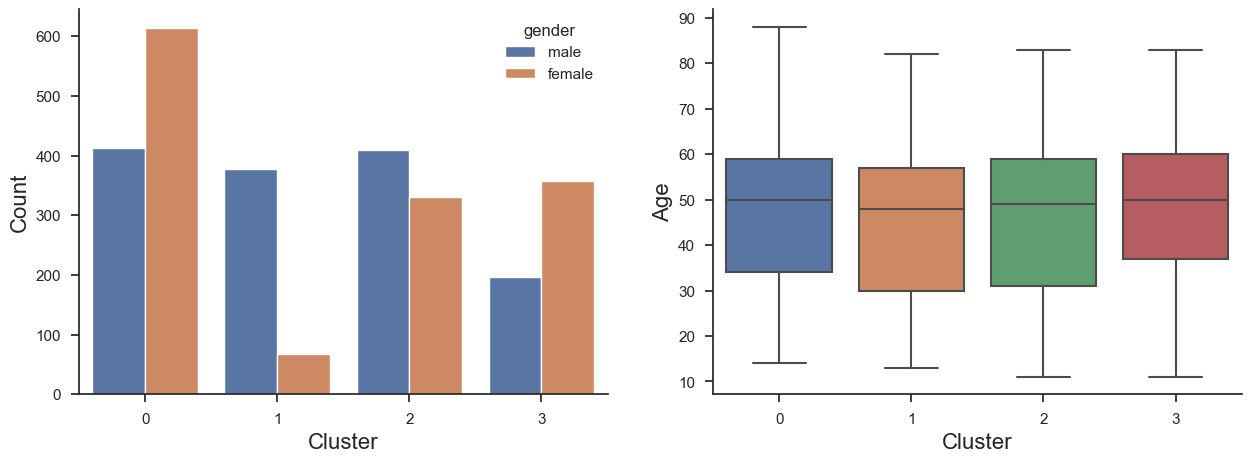

In [40]:
# Initiate grid for plotting with Pyplot
fig, ax = plt.subplots(nrows=1,ncols=2, figsize=(15,5))

# Set theme Seaborn
custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params)

# Left plot
f1 = sns.countplot(ax=ax[0], x="hClus4", hue="gender", data=df)
ax[0].set_xlabel("Cluster", fontsize = 16)
ax[0].set_ylabel("Count", fontsize = 16)

# Right plot
f2 = sns.boxplot(ax=ax[1], x="hClus4", y="Alter01_A", data=df)
ax[1].set_xlabel("Cluster", fontsize = 16)
ax[1].set_ylabel("Age", fontsize = 16)

In [41]:
# Convert DataFrame from wide to long format for plotting
dfLong = pd.melt(df, id_vars=['Unnamed: 0', 'Alter01_A', 'gender', 'kClus', 'hClus', 'hClus4'], value_vars=['ZSKILL_COMP', 'ZBEHAVIOUR', 'ZATTRACTION', 'ZCENTRALITY', 'ZSOCIAL_BONDING'])

Text(0, 0.5, 'Questionaire Metric Score')

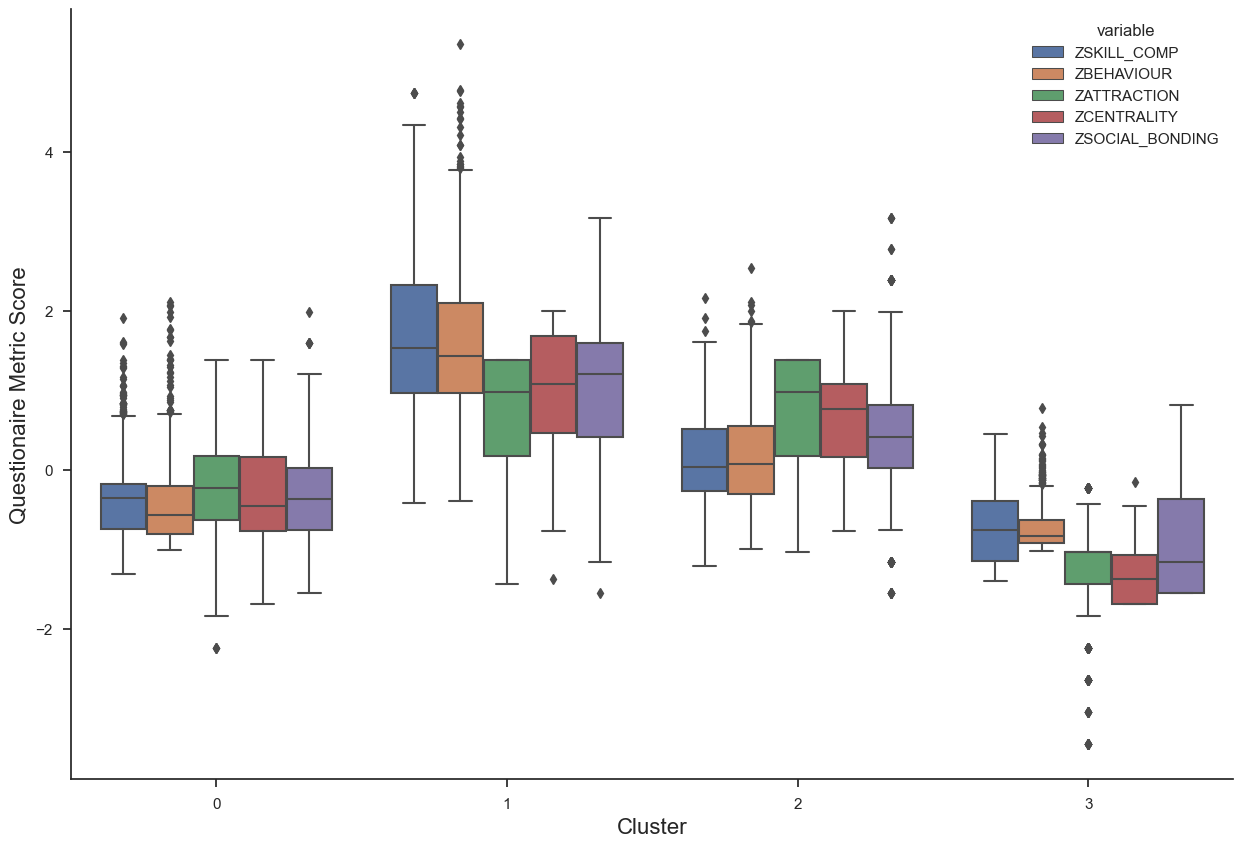

In [42]:
# Initiate grid for plotting with Pyplot
fig, ax = plt.subplots(nrows=1,ncols=1, figsize=(15,10))

# Set theme Seaborn
custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params)

f1 = sns.boxplot(ax=ax, x="hClus4", y="value", data=dfLong, hue="variable")
ax.set_xlabel("Cluster", fontsize = 16)
ax.set_ylabel("Questionaire Metric Score", fontsize = 16)

##### Interpretation
In this graph we still clearly have a beginners group of birdwatchers (cluster 3) and an intermediate group (cluster 0). Interestingly, the expert group seems to be devided in two groups. The first expert group (cluster 1) has the highest skill level and spends most time birding (behaviour metric), while people in both expert groups (cluster 1 and 2) generally say birdwatching is central to their lifestyle and social life.